# AI-Powered Air Quality Intelligence
## AirShift India: a dose-aware planner of low-exposure time windows for outdoor workers and students

**Course:** Foundations of Data Science (FDS), MSc Artificial Intelligence and Machine Learning, VIT Vellore

**Core idea.** Air-quality apps report *how bad* the air is. Outdoor workers and students usually cannot avoid going outside, but they can often shift *when* they go. AirShift forecasts tomorrow's hourly PM2.5 with calibrated uncertainty, converts it into the dose a person actually inhales during a given activity, and recommends the lowest-exposure time window within their working or study hours. It is evaluated by the exposure it would have avoided, not only by forecast accuracy.

**Data.** Hourly PM2.5, PM10, NO2, CO, relative humidity and wind speed from CPCB continuous monitoring stations, **2020 to 2024**, for **43 cities in every region of India** (Kaggle: "India Air Quality Index (AQI) Dataset 2010-2024", station files aggregated to city level by `prepare_data.py`). Breathing rates from U.S. EPA Exposure Factors Handbook (2011), Table 6-2.

**Two groups of cities**
* **Core cities (29):** long, continuous records 2020 to 2024. Used for analysis, training (2020 to 2022), calibration (2023) and testing (2024).
* **New cities (14):** monitoring started later, so they have too little history to train on. Used only to test whether AirShift works in a city it has never seen (2024).

**Phases:** 1 data audit; 2 descriptive statistics and daily patterns; 3 probability, Markov chains and information; 4 correlation and linear algebra; 5 forecasting with calibrated uncertainty; 6 dose model and optimizer; 7 backtest on 2024; 8 new-city test; 9 advisory cards; 10 summary and exports.

**Not claimed:** medical advice, health-risk prediction, real-time deployment, indoor exposure.

## 0. Setup and reproducibility

In [1]:
%matplotlib inline
import sys, json, hashlib, inspect, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.inspection import permutation_importance

sys.path.insert(0, str(Path("src").resolve()))
import airshift_core as ac

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 180); pd.set_option("display.max_rows", 80)
sns.set_theme(style="whitegrid", context="notebook")

DATA, META, SEL = Path("data/india_city_hour_2020_2024.csv.gz"), Path("data/city_meta.csv"), Path("data/station_selection.csv")
OUT = Path("outputs"); FIG, TAB, APP = OUT / "figures", OUT / "tables", OUT / "app"
for p in (FIG, TAB, APP):
    p.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

def savetab(df_, name, index=True):
    df_.to_csv(TAB / f"{name}.csv", index=index); return df_

FIT_END, TRAIN_END, CAL_YEAR, TEST_YEAR = "2021-12-31", "2022-12-31", 2023, 2024
PM25_BINS = [-0.001, 30, 60, 90, 120, 250, np.inf]
CATS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
REGIONS = ["North", "East", "Northeast", "Central", "West", "South"]
REGION_COLORS = {"North": "#B03A2E", "East": "#D68910", "Northeast": "#7D3C98", "Central": "#2E86C1", "West": "#148F77", "South": "#1F618D"}
SEASONS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
def imd_season(month):
    return np.select([np.isin(month, [1, 2]), np.isin(month, [3, 4, 5]), np.isin(month, [6, 7, 8, 9])], SEASONS[:3], SEASONS[3])

sha = hashlib.sha256(DATA.read_bytes()).hexdigest()
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")
print(f"Data: {DATA} | SHA-256 {sha[:16]}...")

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0 | scipy 1.17.1
Data: data/india_city_hour_2020_2024.csv.gz | SHA-256 c9e9803b65aa121d...


## Phase 1. Data audit and city selection

### 1.1 How the city-level table was built (`prepare_data.py`)
1. Each CPCB station in the Kaggle dataset was assigned to the nearest of 46 target cities if it lies within 15 km.
2. Up to three stations per city were downloaded (largest files first). Readings are mostly every 15 minutes; they were averaged to hourly means, keeping an hour only if at least half of its readings exist.
3. Cleaning per station: PM2.5, PM10 and NO2 values of 999 or more (instrument ceiling) or below zero set to missing; CO above 50 mg/m³ set to missing; PM2.5 repeated identically for 6 or more hours (stuck sensor) set to missing.
4. Stations with PM2.5 in at least 50% of hours from 2020 to 2024 form a consistent "long record" city series. If a city had none, stations with at least 50% coverage in 2024 were used instead ("recent only").
5. The city value for each hour is the mean of its stations that reported in that hour.

In [2]:
raw = pd.read_csv(DATA, parse_dates=["Datetime"])
meta = pd.read_csv(META).set_index("City")
sel = pd.read_csv(SEL)
print("Shape:", raw.shape, "| cities:", raw["City"].nunique(), "| from", raw["Datetime"].min(), "to", raw["Datetime"].max())
print("Duplicate City-Datetime rows:", raw.duplicated(["City", "Datetime"]).sum())
display((raw.isna().mean() * 100).round(1).to_frame("missing_%").T)
used = sel[sel["used"] == True]
st_sum = used.groupby("City").agg(stations=("station_code", "size"), ceiling_readings=("ceiling_readings", "sum"), stuck_hours=("stuck_hours", "sum"))
display(savetab(st_sum.join(meta[["State", "Region", "tier"]]).sort_values(["Region", "State"]), "01_stations_used"))
print("Cities in the target list without usable stations:", sorted(set(meta.index) - set(raw["City"].unique())))

Shape: (1885464, 9) | cities: 43 | from 2020-01-01 00:00:00 to 2024-12-31 23:00:00


Duplicate City-Datetime rows: 0


,City,Datetime,PM2.5,PM10,NO2,CO,RH,WS,n_stations
missing_%,0.0,0.0,21.1,24.4,18.3,21.2,23.8,22.2,0.0


,stations,ceiling_readings,stuck_hours,State,Region,tier
City,,,,,,
Bhopal,1,0.0,0.0,Madhya Pradesh,Central,long record
Gwalior,1,0.0,0.0,Madhya Pradesh,Central,long record
Indore,1,0.0,0.0,Madhya Pradesh,Central,long record
Muzaffarpur,1,0.0,0.0,Bihar,East,long record
Patna,3,0.0,0.0,Bihar,East,long record
Raipur,3,0.0,0.0,Chhattisgarh,East,recent only
Bhubaneswar,2,0.0,0.0,Odisha,East,recent only
Kolkata,3,0.0,0.0,West Bengal,East,long record
Chandigarh,3,0.0,0.0,Chandigarh,North,long record


Cities in the target list without usable stations: ['Ranchi', 'Salem', 'Srinagar']


### 1.2 Which cities can be used for what?
**Rules fixed before modelling:**
* **Core city:** PM2.5 present in at least 60% of hours in *every* year 2020 to 2024. Enough history to learn from.
* **New city:** not core, but at least 50% of hours in 2024. Used only to test AirShift in cities it has never seen.

Core cities: 29 | New cities: 14


group,core,new
Region,,
North,11,2
East,3,2
Northeast,1,5
Central,2,1
West,3,2
South,9,2


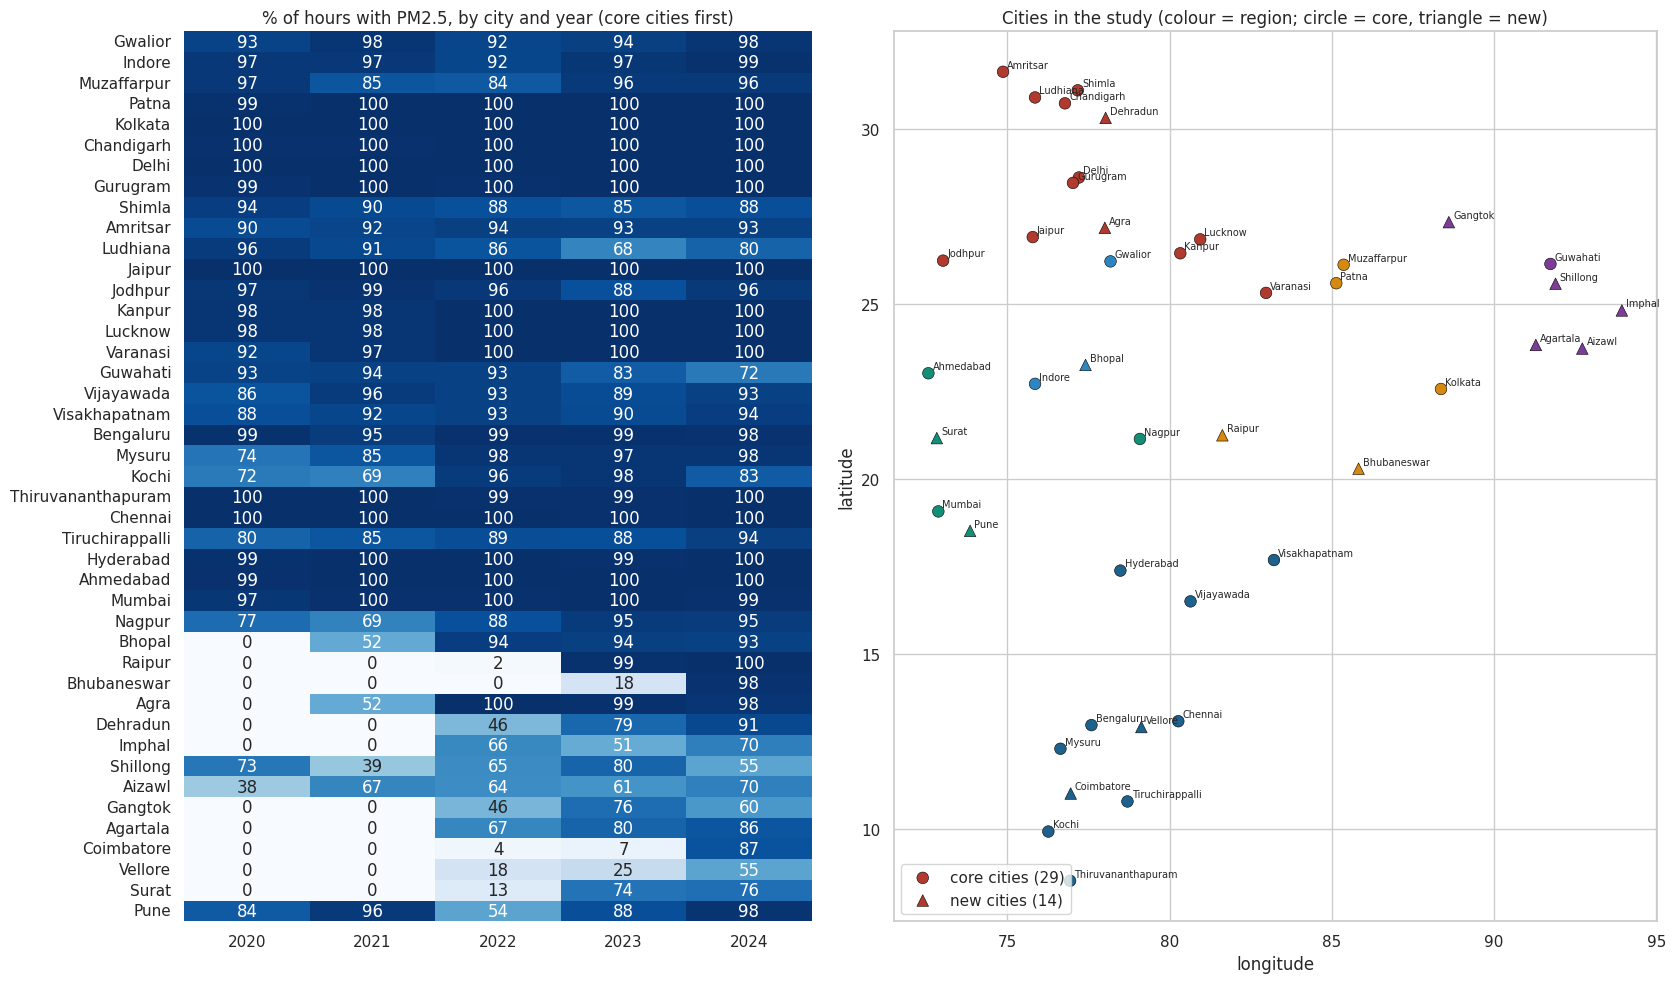

In [3]:
raw["year"] = raw["Datetime"].dt.year
coverage = raw.groupby(["City", "year"])["PM2.5"].apply(lambda s: s.notna().mean() * 100).unstack().round(1)
CORE = sorted(coverage.index[(coverage[[2020, 2021, 2022, 2023, 2024]] >= 60).all(axis=1)])
NEW = sorted(coverage.index[~coverage.index.isin(CORE) & (coverage[2024] >= 50)])
meta["group"] = np.where(meta.index.isin(CORE), "core", np.where(meta.index.isin(NEW), "new", "excluded"))
order = meta.loc[CORE + NEW].sort_values(["group", "Region", "State"]).index
savetab(coverage.loc[order].assign(group=meta.loc[order, "group"], Region=meta.loc[order, "Region"]), "02_coverage_city_year")
print(f"Core cities: {len(CORE)} | New cities: {len(NEW)}")
display(pd.crosstab(meta.loc[CORE + NEW, "Region"], meta.loc[CORE + NEW, "group"]).reindex(REGIONS))

fig, axes = plt.subplots(1, 2, figsize=(17, 10), gridspec_kw={"width_ratios": [1, 1.25]})
sns.heatmap(coverage.loc[order], annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=axes[0])
axes[0].set_title("% of hours with PM2.5, by city and year (core cities first)"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
for grp, mk in [("core", "o"), ("new", "^")]:
    m = meta[meta["group"] == grp]
    axes[1].scatter(m["lon"], m["lat"], c=[REGION_COLORS[r] for r in m["Region"]], marker=mk, s=70, edgecolor="black", lw=0.4,
                    label=f"{grp} cities ({len(m)})")
    for c, r in m.iterrows():
        axes[1].annotate(c, (r["lon"], r["lat"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1].set_aspect(1 / np.cos(np.radians(22))); axes[1].set_xlabel("longitude"); axes[1].set_ylabel("latitude")
axes[1].set_title("Cities in the study (colour = region; circle = core, triangle = new)"); axes[1].legend(loc="lower left")
savefig("01_coverage_and_map")

**Interpretation.** 29 cities qualify as core and 14 as new, and every region of India is represented. The Northeast is the exception that proves the point: five of its six cities only started reporting in 2022 or 2023, so they appear as new cities. About 18% to 24% of values are missing overall, mostly the years before new cities' stations started. Station metadata in the source has quirks (some 'city' labels are agency names such as TNPCB), which is why stations were matched to cities by coordinates.

In [4]:
series = {}
for c, g in raw.groupby("City"):
    series[c] = g.set_index("Datetime").sort_index()[["PM2.5", "PM10", "NO2", "CO", "RH", "WS"]].rename(columns={"PM2.5": "PM25"}).asfreq("h")
hourly = pd.concat({c: series[c] for c in CORE}, names=["City", "Datetime"]).reset_index()
hourly["hour"], hourly["month"], hourly["year"] = hourly["Datetime"].dt.hour, hourly["Datetime"].dt.month, hourly["Datetime"].dt.year
hourly["season"] = imd_season(hourly["month"]); hourly["Region"] = hourly["City"].map(meta["Region"])
print(f"Core hourly table: {len(hourly):,} rows, {hourly['PM25'].notna().sum():,} valid PM2.5 values")

Core hourly table: 1,271,592 rows, 1,205,796 valid PM2.5 values


## Phase 2. Descriptive statistics and daily patterns (core cities, 2020 to 2024)

**Formulas.** Mean $\bar x = \frac1n\sum x_i$; variance $s^2 = \frac{1}{n-1}\sum (x_i-\bar x)^2$; quartiles $Q_1, Q_3$; $\text{IQR} = Q_3 - Q_1$; skewness measures asymmetry. The mode is not reported for continuous concentrations because almost every value is unique.

,n,mean,median,std,Q1,Q3,p95,skew,IQR,Region
City,,,,,,,,,,
Gwalior,41561,60.0,37.5,59.3,19.2,82.0,179.8,2.1,62.8,Central
Indore,42208,45.3,33.8,37.3,22.0,56.5,116.2,3.4,34.5,Central
Patna,43759,81.2,66.8,59.3,36.6,110.1,195.9,1.7,73.5,East
Muzaffarpur,40141,78.4,55.2,73.6,27.2,106.5,223.8,2.2,79.2,East
Kolkata,43795,52.8,37.0,44.2,19.6,75.1,141.2,1.5,55.5,East
Delhi,43802,90.2,69.4,72.1,37.8,122.0,229.8,2.0,84.2,North
Gurugram,43699,70.7,60.0,45.2,37.8,91.9,154.2,1.8,54.1,North
Ludhiana,36876,77.7,59.9,63.7,37.4,96.4,200.8,2.9,59.0,North
Lucknow,43422,64.8,55.9,47.0,30.5,86.9,149.4,2.3,56.3,North


,median,mean,p95
Region,,,
North,49.1,63.4,160.0
East,52.5,70.6,188.2
Northeast,41.5,64.8,194.3
Central,35.0,52.6,151.8
West,36.9,43.6,100.7
South,32.1,42.8,107.8


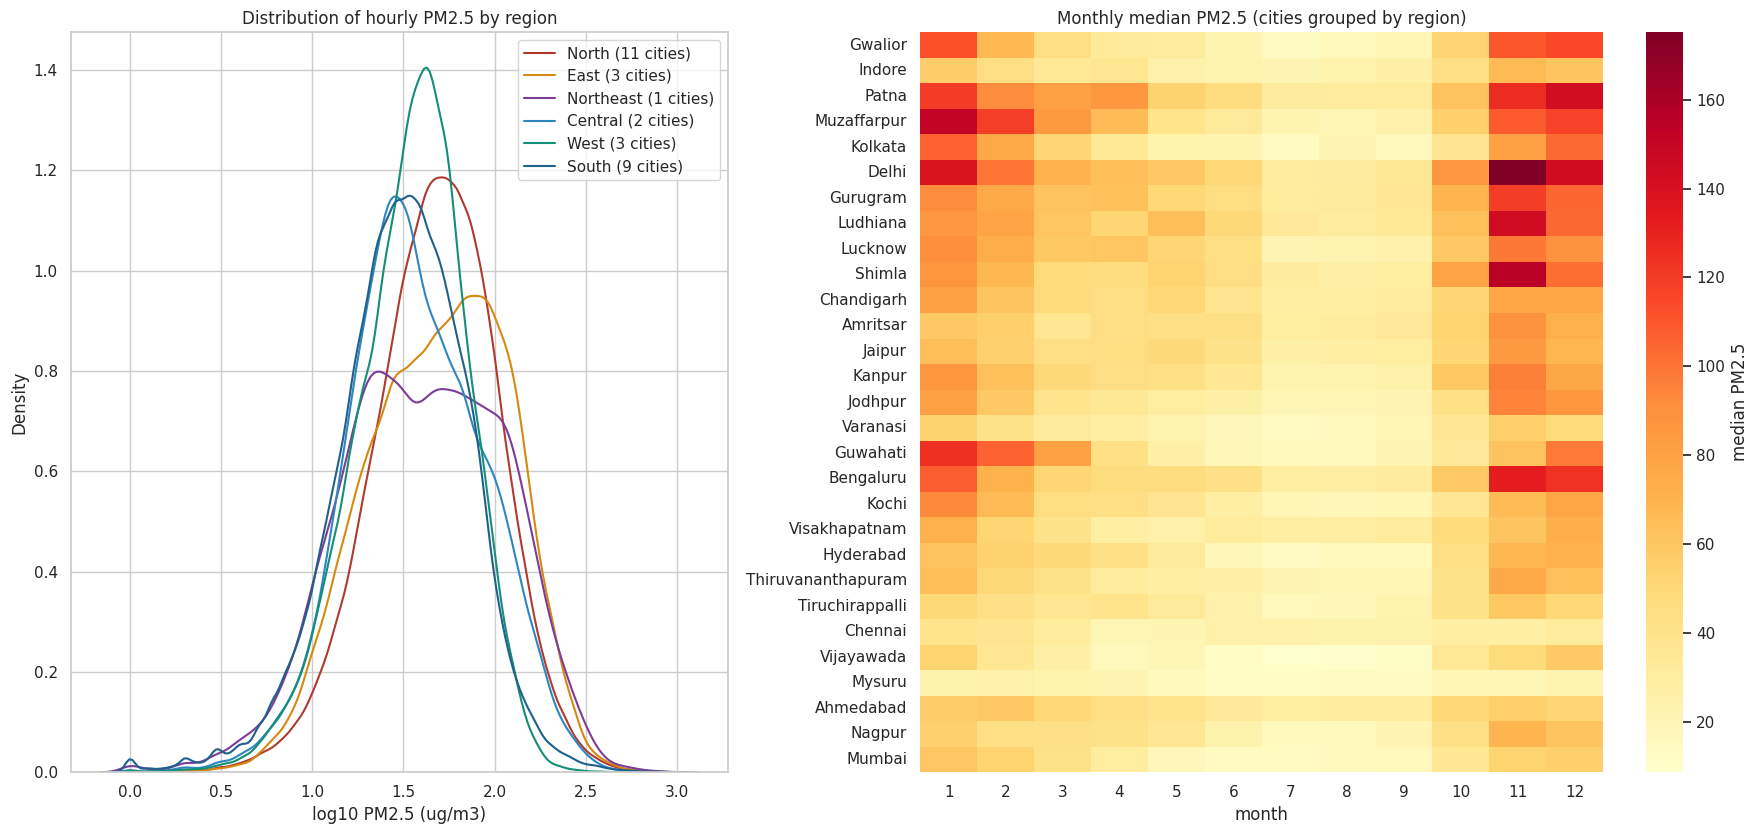

In [5]:
v = hourly.dropna(subset=["PM25"])
desc = v.groupby("City")["PM25"].agg(n="count", mean="mean", median="median", std="std", Q1=lambda s: s.quantile(0.25),
                                     Q3=lambda s: s.quantile(0.75), p95=lambda s: s.quantile(0.95), skew="skew")
desc["IQR"] = desc["Q3"] - desc["Q1"]
desc = desc.join(meta[["Region"]]).sort_values(["Region", "median"], ascending=[True, False])
display(savetab(desc.round(1), "03_descriptive_pm25"))
display(v.groupby("Region")["PM25"].agg(median="median", mean="mean", p95=lambda s: s.quantile(0.95)).reindex(REGIONS).round(1))

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), gridspec_kw={"width_ratios": [1, 1.3]})
for r in REGIONS:
    x = v.loc[v["Region"] == r, "PM25"]
    sns.kdeplot(np.log10(x.clip(lower=1)), ax=axes[0], color=REGION_COLORS[r], label=f"{r} ({v.loc[v['Region'] == r, 'City'].nunique()} cities)")
axes[0].set_xlabel("log10 PM2.5 (ug/m3)"); axes[0].legend(); axes[0].set_title("Distribution of hourly PM2.5 by region")
mon = v.groupby(["City", "month"])["PM25"].median().unstack().loc[desc.index]
sns.heatmap(mon, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "median PM2.5"}); axes[1].set_ylabel("")
axes[1].set_title("Monthly median PM2.5 (cities grouped by region)")
savefig("02_distributions_and_months")

**Interpretation.** Median PM2.5 ranges from 18.7 µg/m³ in Mysuru to 69.4 in Delhi. The Indo-Gangetic plain (Delhi, Gurugram, Ludhiana, Lucknow, Patna, Muzaffarpur) is the most polluted belt, and the southern and western coastal cities are the cleanest. All distributions are right-skewed (skewness 1.2 to 5.4), so medians and log scales are used. The monthly heatmap shows the winter peak in the north (November to January) and the monsoon minimum everywhere.

### 2.1 Daily rhythm: the core motivation
If air quality changes strongly *within* a day, choosing *when* to be outside matters. The heatmap shows each city's median PM2.5 by hour divided by its own daily median, so cities with very different levels can be compared.

,days,median,share_at_least_2x,cleanest_hour_06_21,Region
City,,,,,
Guwahati,1204,4.578,0.952,15,Northeast
Tiruchirappalli,1110,4.044,0.916,14,South
Gwalior,1512,3.526,0.877,15,Central
Jodhpur,1523,3.400,0.882,15,North
Kochi,1020,3.349,0.864,15,South
Muzaffarpur,1469,3.018,0.864,16,East
Bengaluru,1688,2.925,0.819,16,South
Varanasi,1574,2.918,0.865,16,North
Kanpur,1706,2.880,0.822,16,North


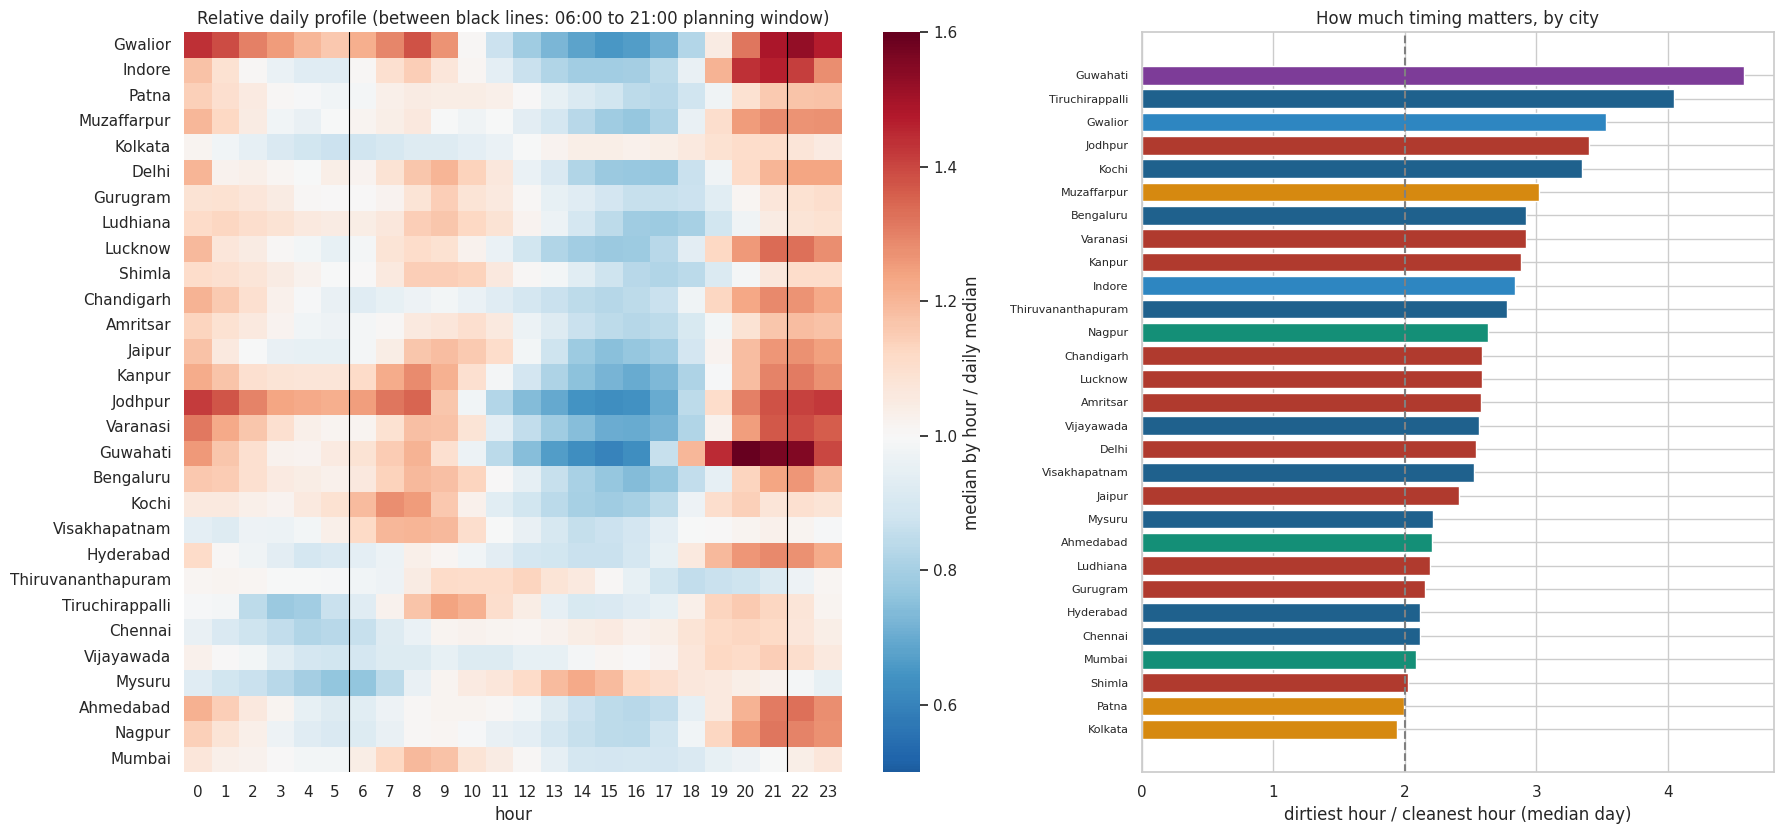

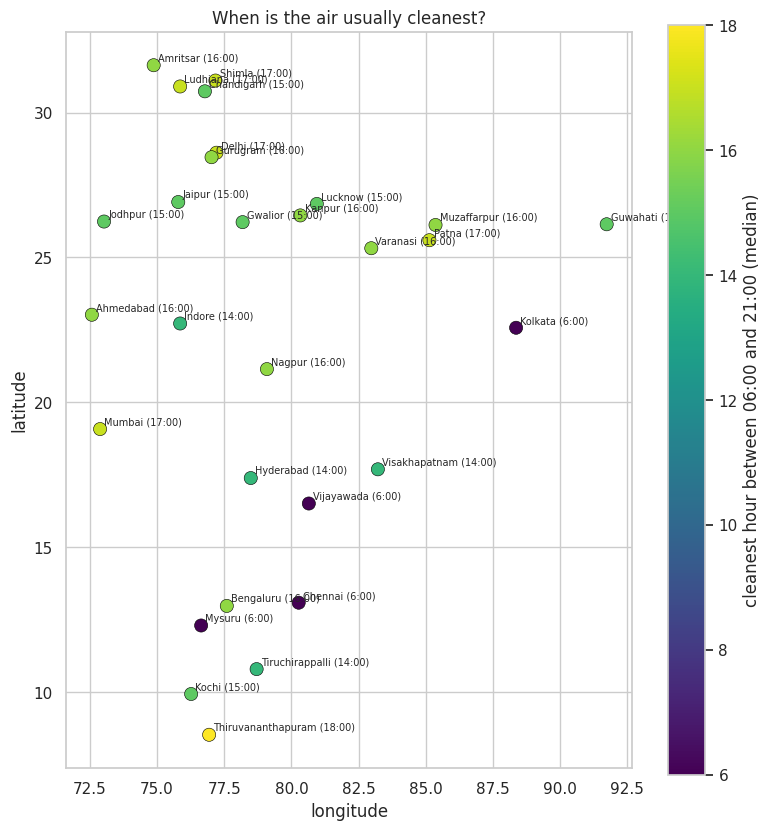

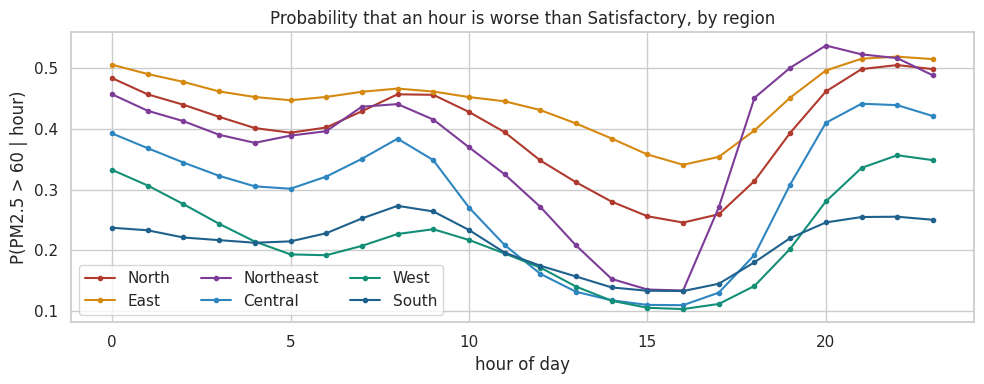

In [6]:
allc = pd.concat({c: series[c] for c in CORE + NEW}, names=["City", "Datetime"]).reset_index().dropna(subset=["PM25"])
allc["hour"] = allc["Datetime"].dt.hour; allc["season"] = imd_season(allc["Datetime"].dt.month)
prof = (allc.groupby(["City", "season", "hour"])["PM25"].agg(median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)).reset_index())
prof.to_csv(APP / "profiles.csv", index=False)

hr = v.groupby(["City", "hour"])["PM25"].median().unstack()
rel = hr.div(v.groupby("City")["PM25"].median(), axis=0).loc[desc.index]
day = v[(v["hour"] >= 6) & (v["hour"] <= 21)].assign(date=lambda d: d["Datetime"].dt.normalize())
g = day.groupby(["City", "date"])["PM25"]
ratio = (g.max() / g.min())[g.count() == 16].rename("max_over_min").reset_index()
timing = ratio.groupby("City")["max_over_min"].agg(days="count", median="median", share_at_least_2x=lambda s: (s >= 2).mean())
cleanest = hr.loc[:, 6:21].idxmin(axis=1).rename("cleanest_hour_06_21")
timing = timing.join(cleanest).join(meta[["Region"]]).sort_values("median", ascending=False)
display(savetab(timing.round(3), "04_within_day_ratio"))

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(rel, cmap="RdBu_r", center=1, vmin=0.5, vmax=1.6, ax=axes[0], cbar_kws={"label": "median by hour / daily median"})
axes[0].axvline(6, color="black", lw=0.8); axes[0].axvline(22, color="black", lw=0.8); axes[0].set_ylabel("")
axes[0].set_title("Relative daily profile (between black lines: 06:00 to 21:00 planning window)")
axes[1].barh(timing.index[::-1], timing["median"][::-1], color=[REGION_COLORS[r] for r in timing["Region"][::-1]])
axes[1].axvline(2, color="grey", ls="--"); axes[1].set_xlabel("dirtiest hour / cleanest hour (median day)")
axes[1].set_title("How much timing matters, by city"); axes[1].tick_params(axis="y", labelsize=8)
savefig("03_daily_rhythm")

fig, ax = plt.subplots(figsize=(8, 8.5))
sc_ = ax.scatter(meta.loc[CORE, "lon"], meta.loc[CORE, "lat"], c=cleanest.loc[CORE], cmap="viridis", s=90, edgecolor="black", lw=0.4)
for c in CORE:
    ax.annotate(f"{c} ({cleanest[c]}:00)", (meta.loc[c, "lon"], meta.loc[c, "lat"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc_, ax=ax, label="cleanest hour between 06:00 and 21:00 (median)")
ax.set_aspect(1 / np.cos(np.radians(22))); ax.set_title("When is the air usually cleanest?"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
savefig("04_cleanest_hour_map")

ex = v.assign(over60=v["PM25"] > 60).groupby(["Region", "hour"])["over60"].mean().unstack(0)[REGIONS]
savetab(ex.round(3), "05_exceedance_by_hour_region")
fig, ax = plt.subplots(figsize=(10, 4))
for r in REGIONS:
    ax.plot(ex.index, ex[r], color=REGION_COLORS[r], marker="o", ms=3, label=r)
ax.set_xlabel("hour of day"); ax.set_ylabel("P(PM2.5 > 60 | hour)"); ax.legend(ncol=3); ax.set_title("Probability that an hour is worse than Satisfactory, by region")
savefig("05_exceedance_by_hour")

**Interpretation.** This is the central motivation for AirShift, now confirmed across India. Within 06:00 to 21:00, the dirtiest hour is typically 1.9 (Kolkata) to 4.6 (Guwahati) times the cleanest, and in every core city at least 45% of days have a two-fold difference (up to 95% in Guwahati). In 25 of 29 cities the cleanest hour is usually between 14:00 and 18:00, when the daytime mixing layer is deepest; in Kolkata, Chennai, Vijayawada and Mysuru it is 06:00. The exceedance curves show the same afternoon dip in every region. Because the clean window differs by city, a single national rule would fail for part of the country.

## Phase 3. Probability, Markov chains and information

Each hour gets an official PM2.5 category (Good 0 to 30, Satisfactory 31 to 60, Moderate 61 to 90, Poor 91 to 120, Very Poor 121 to 250, Severe above 250 µg/m³). The official index uses 24-hour averages, so hourly categories are *indicative*.

### 3.1 Markov chain and its stationary distribution
$P_{ij} = P(C_{t+1} = j \mid C_t = i) = n_{ij}/\sum_k n_{ik}$, estimated on 2020 to 2022. The stationary distribution satisfies $\pi P = \pi$: it is the left eigenvector of $P$ for eigenvalue 1.

,max_abs_pi_minus_empirical,pi_Good,pi_Satisfactory,pi_Moderate,pi_Poor,pi_Very Poor,pi_Severe,Region
City,,,,,,,,
Gwalior,0.003,0.424,0.222,0.118,0.084,0.135,0.017,Central
Indore,0.001,0.453,0.331,0.122,0.054,0.038,0.002,Central
Kolkata,0.001,0.434,0.214,0.133,0.100,0.115,0.003,East
Muzaffarpur,0.001,0.300,0.213,0.129,0.089,0.216,0.052,East
Patna,0.001,0.234,0.283,0.193,0.121,0.156,0.013,East
Amritsar,0.001,0.324,0.384,0.182,0.068,0.041,0.001,North
Chandigarh,0.000,0.303,0.376,0.206,0.077,0.037,0.000,North
Delhi,0.000,0.207,0.259,0.179,0.119,0.205,0.031,North
Gurugram,0.001,0.165,0.346,0.222,0.132,0.127,0.007,North


Largest |pi - empirical| over all cities: 0.0315


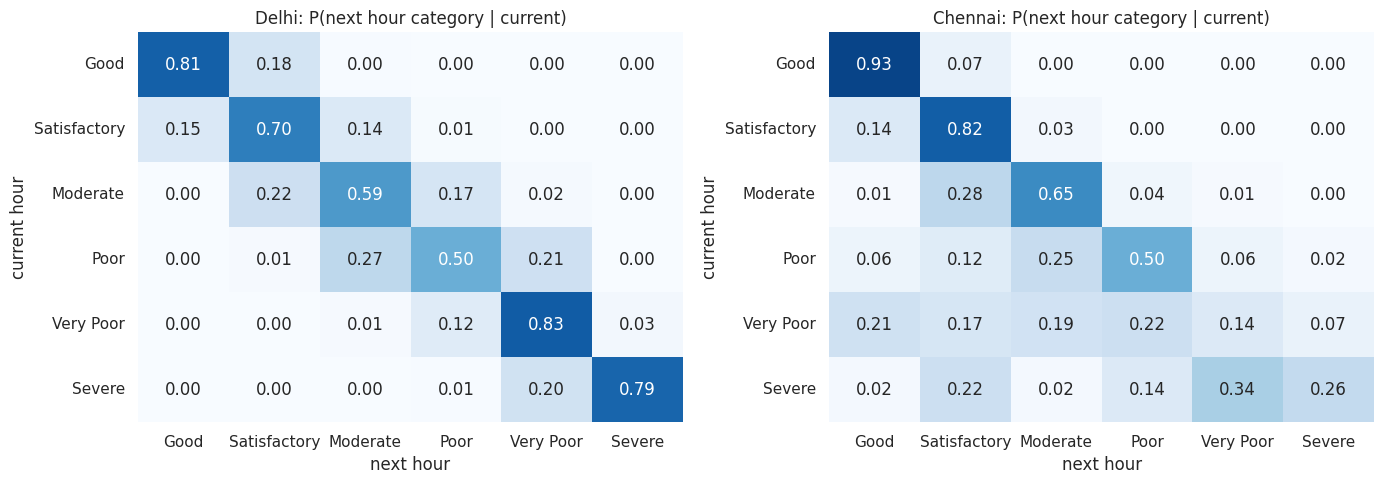

In [7]:
K = len(CATS)
def codes_of(s):
    return pd.cut(s, PM25_BINS, labels=False)

P_hom, P_hour, devs = {}, {}, []
for c in CORE:
    s = series[c]["PM25"]; cc = codes_of(s).to_numpy(); tr = (s.index <= TRAIN_END)
    prev, nxt = cc[:-1], cc[1:]
    ok = ~np.isnan(prev) & ~np.isnan(nxt) & tr[1:] & tr[:-1]
    cnt = np.zeros((K, K)); np.add.at(cnt, (prev[ok].astype(int), nxt[ok].astype(int)), 1)
    hc = np.zeros((24, K, K)); np.add.at(hc, (s.index.hour[1:][ok], prev[ok].astype(int), nxt[ok].astype(int)), 1)
    P_hom[c] = (cnt + 0.5) / (cnt + 0.5).sum(axis=1, keepdims=True)
    P_hour[c] = (hc + 0.5) / (hc + 0.5).sum(axis=2, keepdims=True)
    ev, evec = np.linalg.eig(P_hom[c].T)
    pi = np.real(evec[:, np.argmin(np.abs(ev - 1))]); pi /= pi.sum()
    emp = np.bincount(cc[tr & ~np.isnan(cc)].astype(int), minlength=K) / np.sum(tr & ~np.isnan(cc))
    devs.append({"City": c, "max_abs_pi_minus_empirical": np.abs(pi - emp).max(), **{f"pi_{k}": p for k, p in zip(CATS, pi)}})
stat = pd.DataFrame(devs).set_index("City")
display(savetab(stat.round(3).join(meta[["Region"]]).sort_values("Region"), "06_stationary_distribution"))
print("Largest |pi - empirical| over all cities:", round(float(stat["max_abs_pi_minus_empirical"].max()), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, c in zip(axes, ["Delhi", "Chennai"]):
    sns.heatmap(pd.DataFrame(P_hom[c], index=CATS, columns=CATS), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"{c}: P(next hour category | current)"); ax.set_ylabel("current hour"); ax.set_xlabel("next hour")
savefig("06_transition_matrices")

**Interpretation.** The stationary distribution from the eigenvector matches the observed category shares within 0.003 in almost every city (0.018 at most, in Shimla, where data gaps are larger). The chains are strongly persistent. The distributions differ sharply: Delhi spends about 21% of hours in Very Poor and 3% in Severe, while Indore is Good 45% of the time.

### 3.2 Forecasting tomorrow's categories with a time-inhomogeneous Markov chain
Standing at 21:00 the evening before (state $s$), the category distribution at hour $h$ tomorrow is $\mathbf{p}_h = \mathbf{e}_s\,P^{(22)}P^{(23)}P^{(0)}\cdots P^{(h)}$, a product of hour-specific matrices. It is compared with the single-matrix chain ($\mathbf{e}_s P^{n}$) and with climatology (category frequencies by city, month and hour, 2020 to 2022). Score on 2024: log loss $-\frac1N\sum\log p(\text{true})$ and accuracy.

,ll_inhomog,ll_homog,ll_clim,acc_inhomog,acc_homog,acc_clim
Region,,,,,,
North,1.267,1.298,1.268,0.482,0.490,0.458
East,1.245,1.289,1.309,0.431,0.409,0.435
Northeast,1.308,1.399,1.166,0.436,0.388,0.524
Central,1.199,1.252,1.053,0.468,0.449,0.529
West,0.986,1.007,1.003,0.546,0.549,0.579
South,1.080,1.088,0.993,0.517,0.492,0.569
All core cities,1.173,1.201,1.141,0.492,0.483,0.509


Cities where the hour-specific chain beats climatology on log loss: 7 of 29


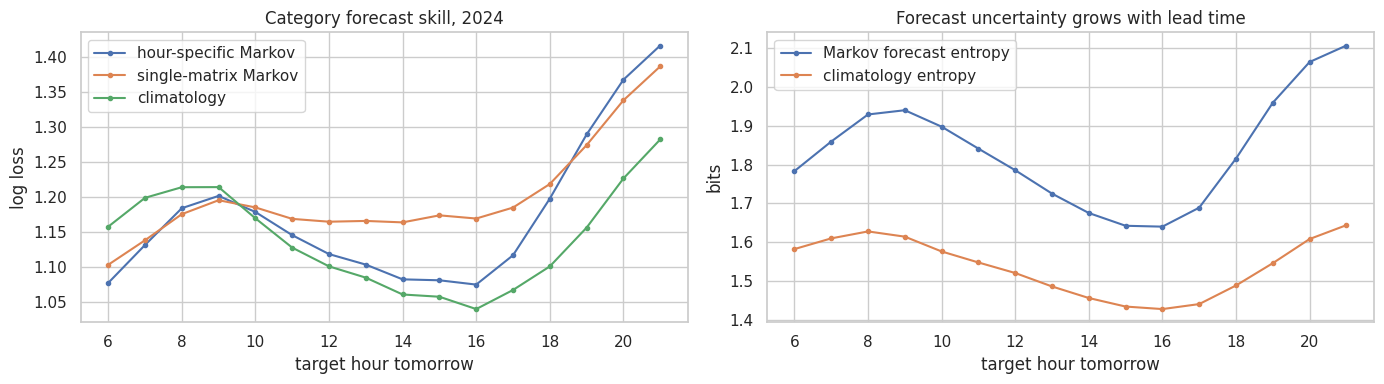

In [8]:
def day_index(s, days):
    pos = s.index.get_indexer(days)
    return pos

clim_cat = {}
for c in CORE:
    s = series[c]["PM25"]; cc = codes_of(s); m = (s.index <= TRAIN_END) & cc.notna().to_numpy()
    tab = np.zeros((13, 24, K)); np.add.at(tab, (s.index.month[m], s.index.hour[m], cc[m].astype(int).to_numpy()), 1)
    clim_cat[c] = (tab + 0.5) / (tab + 0.5).sum(axis=2, keepdims=True)

rows = []
days = pd.date_range(f"{TEST_YEAR}-01-01", f"{TEST_YEAR}-12-31", freq="D")
for c in CORE:
    s = series[c]["PM25"]; cc = codes_of(s).to_numpy(); cs = codes_of(s.ffill(limit=3)).to_numpy()
    pos = day_index(s, days); okd = pos >= 3
    pos, dd = pos[okd], days[okd]
    state = cs[pos - 3]
    A = np.eye(K)
    for h in [22, 23] + list(range(6)):
        A = A @ P_hour[c][h]
    for h in range(6, 22):
        A = A @ P_hour[c][h]
        y = cc[pos + h]; ok = ~np.isnan(state) & ~np.isnan(y)
        st_, yy = state[ok].astype(int), y[ok].astype(int)
        pin = A[st_]; ph = np.linalg.matrix_power(P_hom[c], 3 + h)[st_]; pc = clim_cat[c][dd[ok].month, h]
        idx = np.arange(len(yy))
        rows.append(pd.DataFrame({"City": c, "hour": h,
            "ll_inhomog": -np.log(pin[idx, yy]), "ll_homog": -np.log(ph[idx, yy]), "ll_clim": -np.log(pc[idx, yy]),
            "acc_inhomog": pin.argmax(1) == yy, "acc_homog": ph.argmax(1) == yy, "acc_clim": pc.argmax(1) == yy,
            "H_inhomog": stats.entropy(pin.T, base=2), "H_clim": stats.entropy(pc.T, base=2)}))
mk = pd.concat(rows); mk["Region"] = mk["City"].map(meta["Region"])
cols = ["ll_inhomog", "ll_homog", "ll_clim", "acc_inhomog", "acc_homog", "acc_clim"]
mk_sum = mk.groupby("Region")[cols].mean().reindex(REGIONS); mk_sum.loc["All core cities"] = mk[cols].mean()
display(savetab(mk_sum.round(3), "07_markov_forecast_2024"))
print("Cities where the hour-specific chain beats climatology on log loss:",
      int((mk.groupby("City")["ll_inhomog"].mean() < mk.groupby("City")["ll_clim"].mean()).sum()), "of", len(CORE))

byh = mk.groupby("hour")[["ll_inhomog", "ll_homog", "ll_clim", "H_inhomog", "H_clim"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for col, lab in [("ll_inhomog", "hour-specific Markov"), ("ll_homog", "single-matrix Markov"), ("ll_clim", "climatology")]:
    axes[0].plot(byh.index, byh[col], marker="o", ms=3, label=lab)
axes[0].set_xlabel("target hour tomorrow"); axes[0].set_ylabel("log loss"); axes[0].legend(); axes[0].set_title("Category forecast skill, 2024")
axes[1].plot(byh.index, byh["H_inhomog"], marker="o", ms=3, label="Markov forecast entropy")
axes[1].plot(byh.index, byh["H_clim"], marker="o", ms=3, label="climatology entropy")
axes[1].set_xlabel("target hour tomorrow"); axes[1].set_ylabel("bits"); axes[1].legend(); axes[1].set_title("Forecast uncertainty grows with lead time")
savefig("07_markov_by_hour")

**Interpretation.** Across all core cities, climatology is slightly better than the hour-specific Markov chain (log loss 1.14 against 1.17; accuracy 51% against 49%). The chain wins in the East and roughly ties in the North and West, but loses in the South, Central India and the Northeast; it beats climatology in only 7 of 29 cities. The lesson is the same as before: 9 to 24 hours ahead a first-order chain has forgotten most of tonight's state, while climatology knows the season. A good forecast must combine both, which the machine-learning model does.

### 3.3 Conditional probability and information gain
$P(A\mid B) = P(A\cap B)/P(B)$. **Information gain** of tonight's state $S$ about hour $h$ tomorrow: $IG_h = H(C_h) - H(C_h\mid S)$ with $H(Y) = -\sum p\log_2 p$ and $H(Y\mid X) = \sum_x P(x)H(Y\mid X=x)$.

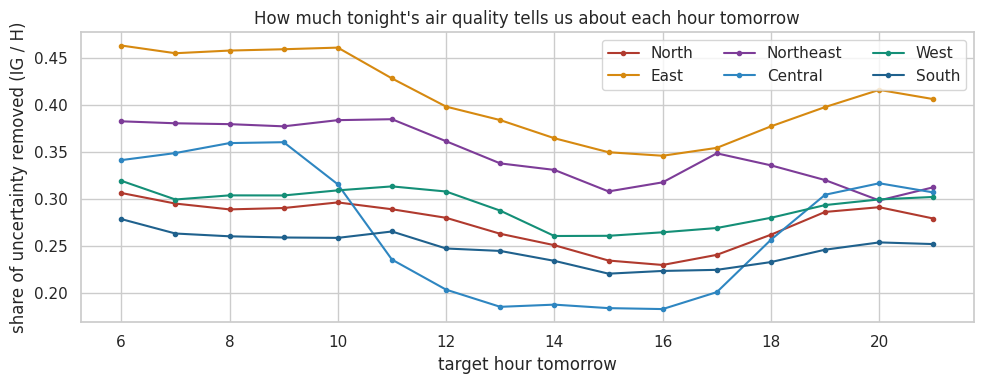

,min,mean,max
Region,,,
North,0.163,0.274,0.432
East,0.326,0.408,0.514
Northeast,0.298,0.348,0.385
Central,0.110,0.268,0.398
West,0.115,0.292,0.403
South,0.043,0.248,0.436


Delhi: P(hour h tomorrow is Poor or worse | category at 21:00 tonight), 2020 to 2022


hour,6,9,12,15,18,21
Good,0.000,0.006,0.000,0.000,0.000,0.018
Satisfactory,0.043,0.066,0.023,0.023,0.023,0.027
Moderate,0.176,0.316,0.124,0.088,0.078,0.290
Poor,0.543,0.682,0.395,0.155,0.171,0.705
Very Poor,0.829,0.886,0.801,0.487,0.576,0.911
Severe,1.000,1.000,0.972,0.917,0.917,1.000


In [9]:
def H(p):
    p = np.asarray(p, dtype=float); p = p[p > 0] / p.sum(); return float(-(p * np.log2(p)).sum())

tdays = pd.date_range("2020-01-02", TRAIN_END, freq="D")
ig_rows, pairs_delhi = [], None
for c in CORE:
    s = series[c]["PM25"]; cc = codes_of(s).to_numpy(); cs = codes_of(s.ffill(limit=3)).to_numpy()
    pos = day_index(s, tdays); pos = pos[pos >= 3]; state = cs[pos - 3]
    for h in range(6, 22):
        y = cc[pos + h]; ok = ~np.isnan(state) & ~np.isnan(y)
        st_, yy = state[ok].astype(int), y[ok].astype(int)
        Hy = H(np.bincount(yy, minlength=K))
        Hc = sum((st_ == k).mean() * H(np.bincount(yy[st_ == k], minlength=K)) for k in np.unique(st_))
        ig_rows.append({"City": c, "hour": h, "H_Y": Hy, "IG": Hy - Hc, "IG_share": (Hy - Hc) / Hy if Hy > 0 else np.nan})
        if c == "Delhi":
            pairs_delhi = pd.concat([pairs_delhi, pd.DataFrame({"state": st_, "y": yy, "hour": h})])
ig = pd.DataFrame(ig_rows); ig["Region"] = ig["City"].map(meta["Region"])
savetab(ig.round(4), "08_information_gain", index=False)
igr = ig.groupby(["Region", "hour"])["IG_share"].mean().unstack(0)[REGIONS]
fig, ax = plt.subplots(figsize=(10, 4))
for r in REGIONS:
    ax.plot(igr.index, igr[r], color=REGION_COLORS[r], marker="o", ms=3, label=r)
ax.set_xlabel("target hour tomorrow"); ax.set_ylabel("share of uncertainty removed (IG / H)"); ax.legend(ncol=3)
ax.set_title("How much tonight's air quality tells us about each hour tomorrow")
savefig("08_information_gain")
display(ig.groupby("Region")["IG_share"].agg(["min", "mean", "max"]).reindex(REGIONS).round(3))
cond = pairs_delhi.assign(poor=pairs_delhi["y"] >= 3).groupby(["state", "hour"])["poor"].mean().unstack()
cond.index = [CATS[i] for i in cond.index]
print("Delhi: P(hour h tomorrow is Poor or worse | category at 21:00 tonight), 2020 to 2022")
display(savetab(cond[[6, 9, 12, 15, 18, 21]].round(3), "09_conditional_poor_delhi"))

**Interpretation.** Tonight's category removes on average 25% (South) to 41% (East) of the uncertainty about tomorrow's hours, and least in the afternoon. The Delhi table shows the practical meaning: after a Very Poor evening, the chance that 09:00 tomorrow is Poor or worse is 0.89, but at 15:00 it is 0.49; after a Satisfactory evening it stays below 0.07 all day.

## Phase 4. Correlation and linear algebra

### 4.1 Autocorrelation, and correlation with co-pollutants and measured weather
Autocorrelation $\rho_k = \operatorname{cov}(x_t, x_{t-k})/\sigma^2$. Spearman's $\rho$ (Pearson on ranks) is used for cross-correlations because the data are skewed. Relative humidity (RH) and wind speed (WS) are measured at the stations, so their relationship with PM2.5 can be studied directly.

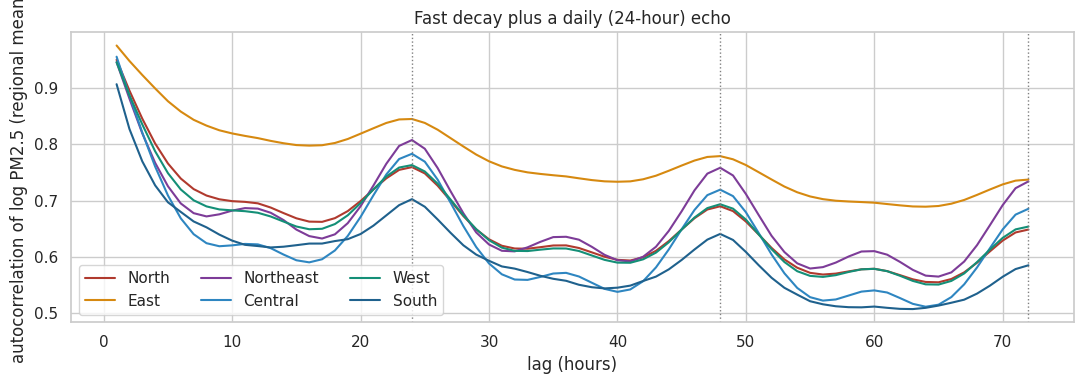

Region,North,East,Northeast,Central,West,South
1,0.951,0.976,0.946,0.956,0.946,0.907
12,0.695,0.811,0.686,0.622,0.679,0.619
24,0.760,0.845,0.808,0.783,0.763,0.703
48,0.690,0.779,0.759,0.720,0.694,0.641


,PM10,NO2,CO,RH,WS
Region,,,,,
North,0.877,0.454,0.427,-0.079,-0.286
East,0.958,0.307,0.442,-0.148,-0.307
Northeast,0.962,0.121,0.804,-0.080,-0.323
Central,0.860,0.619,0.482,0.014,-0.444
West,0.897,0.530,0.435,-0.309,-0.200
South,0.847,0.363,0.294,-0.150,-0.217


Cities where PM2.5 falls as wind speed rises (rho < 0): 26 of 28


In [10]:
lags = list(range(1, 73))
acf = pd.DataFrame({c: [np.log1p(series[c]["PM25"]).autocorr(l) for l in lags] for c in CORE}, index=lags)
acf_r = acf.T.groupby(meta.loc[CORE, "Region"]).mean().T[REGIONS]
savetab(acf.round(4), "10_autocorrelation")
fig, ax = plt.subplots(figsize=(11, 4))
for r in REGIONS:
    ax.plot(acf_r.index, acf_r[r], color=REGION_COLORS[r], label=r)
for L in (24, 48, 72):
    ax.axvline(L, color="grey", ls=":", lw=1)
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation of log PM2.5 (regional mean)"); ax.legend(ncol=3)
ax.set_title("Fast decay plus a daily (24-hour) echo")
savefig("09_autocorrelation")
display(acf_r.loc[[1, 12, 24, 48]].round(3))

xc = pd.DataFrame({c: {p: series[c]["PM25"].corr(series[c][p], method="spearman") for p in ["PM10", "NO2", "CO", "RH", "WS"]} for c in CORE}).T
xc["Region"] = meta.loc[CORE, "Region"]
display(savetab(xc.groupby("Region").mean().reindex(REGIONS).round(3), "11_spearman_by_region"))
xc.round(3).to_csv(TAB / "11b_spearman_by_city.csv")
print("Cities where PM2.5 falls as wind speed rises (rho < 0):", int((xc["WS"] < 0).sum()), "of", int(xc["WS"].notna().sum()))

**Interpretation.** Autocorrelation at lag 24 (0.70 to 0.85 by region) is higher than at lag 12 (0.62 to 0.81): today's hour resembles the same hour yesterday. With real station meteorology, the physics shows up clearly: PM2.5 falls as wind speed rises in 26 of 28 cities (regional mean Spearman -0.20 to -0.44), because wind disperses pollution. Humidity has only a weak, mostly negative link. PM2.5 is strongly tied to PM10 (0.85 to 0.96), and to CO in the Northeast (0.80), consistent with combustion sources.

### 4.2 Eigen-days: PCA and SVD of 24-hour profiles
Each day is a vector $\mathbf{x}\in\mathbb{R}^{24}$ of hourly log PM2.5; stacking days gives $X$ (days × 24). Subtracting each day's own mean keeps only its *shape*. PCA solves $\Sigma\mathbf{v}_k=\lambda_k\mathbf{v}_k$; SVD gives $Z = USV^\top$ with the same loadings and $\lambda_k = s_k^2/(n-1)$.

Day matrix: 24,972 complete city-days x 24 hours
SVD check, s^2/(n-1) equals PCA eigenvalues: True
SVD check, |V| equals |PCA loadings|: True


,explained_ratio,cumulative
PC1,0.3509,0.3509
PC2,0.2126,0.5635
PC3,0.1018,0.6653
PC4,0.0679,0.7333
PC5,0.0509,0.7841
PC6,0.0401,0.8243


Silhouette by k: {2: 0.29, 3: 0.249, 4: 0.247, 5: 0.226, 6: 0.213} -> k = 2


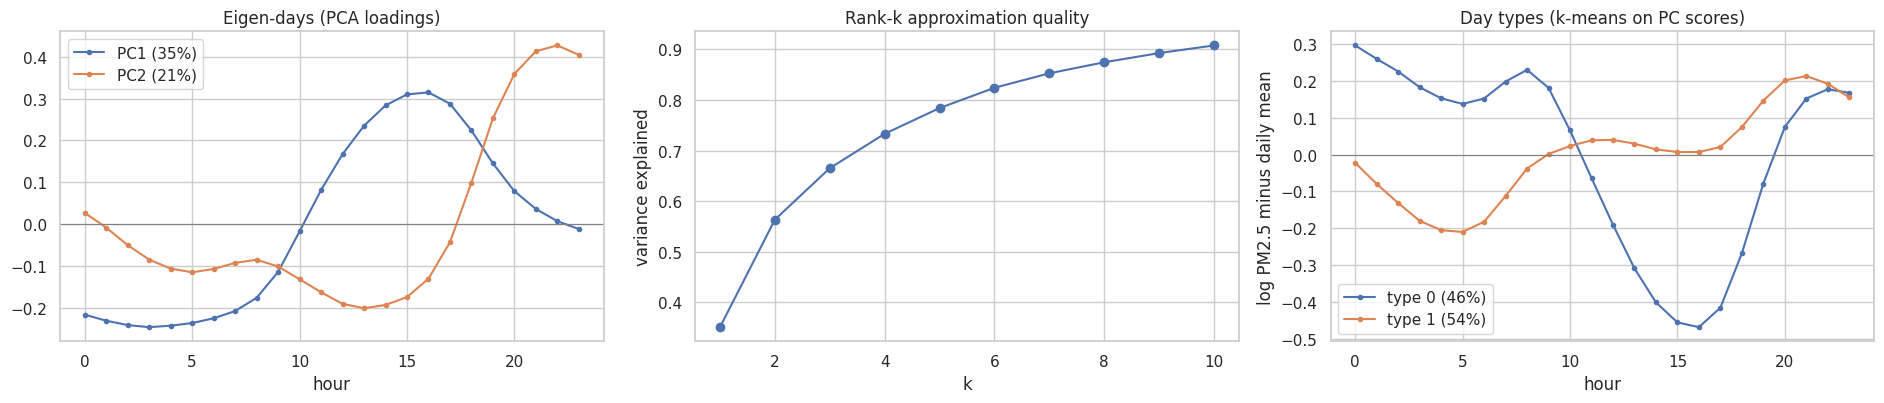

day_type,0,1
Region,,
North,0.530,0.470
East,0.454,0.546
Northeast,0.654,0.346
Central,0.570,0.430
West,0.421,0.579
South,0.345,0.655


day_type,0,1
season,,
Winter,0.577,0.423
Pre-monsoon,0.504,0.496
Monsoon,0.273,0.727
Post-monsoon,0.587,0.413


In [11]:
mats = []
for c in CORE:
    s = np.log1p(series[c]["PM25"][series[c].index <= TRAIN_END])
    m = s.to_frame("v").assign(date=s.index.normalize(), hour=s.index.hour).pivot_table(index="date", columns="hour", values="v")
    mats.append(m[m.notna().sum(axis=1) == 24].assign(City=c))
days_m = pd.concat(mats).reset_index()
Xd = days_m[list(range(24))].to_numpy(); shape = Xd - Xd.mean(axis=1, keepdims=True); Z = shape - shape.mean(axis=0)
print(f"Day matrix: {Xd.shape[0]:,} complete city-days x 24 hours")
pca = PCA().fit(Z); U, S, Vt = np.linalg.svd(Z, full_matrices=False)
print("SVD check, s^2/(n-1) equals PCA eigenvalues:", np.allclose(S ** 2 / (len(Z) - 1), pca.explained_variance_))
print("SVD check, |V| equals |PCA loadings|:", np.allclose(np.abs(Vt[:5]), np.abs(pca.components_[:5])))
ev = pd.DataFrame({"explained_ratio": pca.explained_variance_ratio_[:6], "cumulative": np.cumsum(pca.explained_variance_ratio_)[:6]}, index=[f"PC{i}" for i in range(1, 7)])
display(savetab(ev.round(4), "12_eigenday_variance"))
scores = pca.transform(Z)[:, :3]
sub = np.random.default_rng(SEED).choice(len(scores), size=min(4000, len(scores)), replace=False)
sil = {k: silhouette_score(scores[sub], KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(scores[sub])) for k in range(2, 7)}
k_best = max(sil, key=sil.get)
days_m["day_type"] = KMeans(n_clusters=k_best, n_init=10, random_state=SEED).fit_predict(scores)
days_m["season"] = imd_season(days_m["date"].dt.month); days_m["Region"] = days_m["City"].map(meta["Region"])
print("Silhouette by k:", {k: round(v_, 3) for k, v_ in sil.items()}, "-> k =", k_best)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
for i in range(2):
    axes[0].plot(range(24), pca.components_[i], marker="o", ms=3, label=f"PC{i+1} ({pca.explained_variance_ratio_[i]:.0%})")
axes[0].axhline(0, color="grey", lw=0.8); axes[0].set_xlabel("hour"); axes[0].legend(); axes[0].set_title("Eigen-days (PCA loadings)")
axes[1].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_)[:10], marker="o"); axes[1].set_xlabel("k"); axes[1].set_ylabel("variance explained")
axes[1].set_title("Rank-k approximation quality")
for t in range(k_best):
    axes[2].plot(range(24), shape[days_m["day_type"] == t].mean(axis=0), marker="o", ms=3, label=f"type {t} ({(days_m['day_type'] == t).mean():.0%})")
axes[2].axhline(0, color="grey", lw=0.8); axes[2].set_xlabel("hour"); axes[2].set_ylabel("log PM2.5 minus daily mean"); axes[2].legend()
axes[2].set_title("Day types (k-means on PC scores)")
savefig("10_eigendays")
display(savetab(pd.crosstab(days_m["Region"], days_m["day_type"], normalize="index").reindex(REGIONS).round(3), "13_daytype_by_region"))
display(pd.crosstab(days_m["season"], days_m["day_type"], normalize="index").reindex(SEASONS).round(3))

**Interpretation.** Both SVD checks pass. PC1 (35%) contrasts a clean afternoon with dirty nights and mornings; PC2 (21%) captures an evening peak. Two components explain 56% and four explain 73%. k-means (k = 2 by silhouette) finds two day types: type 0 (46% of days) has a deep afternoon minimum; type 1 (54%) is cleanest around 05:00, flat through the day, and peaks in the evening. Type 1 dominates the monsoon (73% of days) and the South (65%), while the Northeast is mostly type 0 (65%). The best time to be outside therefore depends on region, season and day, which is what AirShift has to predict.

## Phase 5. Forecasting tomorrow's hourly PM2.5 with calibrated uncertainty

**Set-up.** A forecast is issued at **21:00 on the evening before** for each hour from 06:00 to 21:00 tomorrow; one model covers all target hours (target hour is a feature) and all core cities.

**Features (all known at 21:00):** log PM2.5 now, mean of the last 6 and 24 hours, 3-hour change, same hour yesterday, mean of the same hour over the last 7 days, 24-hour means of PM10, NO2, CO, **relative humidity and wind speed measured at the stations**, wind speed now, target hour, day of week, month, and city. Input gaps are filled only by carrying the last value forward (at most 3 hours).

**Target:** $\log(1+\text{PM2.5})$. **Splits:** model choice on fit 2020 to 2021 vs validation 2022; final training 2020 to 2022; calibration 2023; test 2024.

In [12]:
FEATS = ["l_pm_T", "l_pm_mean6", "l_pm_mean24", "l_pm_delta3", "l_same_h_yday", "l_same_h_mean7", "l_pm10_24", "l_no2_24", "l_co_24",
         "rh_24", "ws_24", "ws_T", "hour", "hour_sin", "hour_cos", "dow", "weekend", "month_sin", "month_cos"]

def build_frame(c):
    d = series[c]; s = d["PM25"]; sf = s.ffill(limit=3); f = lambda x: x.ffill(limit=3)
    T_feats = pd.DataFrame({
        "l_pm_T": np.log1p(sf), "l_pm_mean6": np.log1p(sf.rolling(6, min_periods=4).mean()),
        "l_pm_mean24": np.log1p(sf.rolling(24, min_periods=18).mean()), "l_pm_delta3": np.log1p(sf) - np.log1p(sf.shift(3)),
        "l_pm10_24": np.log1p(f(d["PM10"]).rolling(24, min_periods=12).mean()), "l_no2_24": np.log1p(f(d["NO2"]).rolling(24, min_periods=12).mean()),
        "l_co_24": np.log1p(f(d["CO"]).rolling(24, min_periods=12).mean()),
        "rh_24": f(d["RH"]).rolling(24, min_periods=12).mean(), "ws_24": f(d["WS"]).rolling(24, min_periods=12).mean(), "ws_T": f(d["WS"])})
    t = s.index[s.index.hour.isin(ac.FORECAST_HOURS)]
    T = t.normalize() - pd.Timedelta(hours=3)
    assert ((t - pd.Timedelta(hours=24)) <= T).all() and (T < t).all()
    X = T_feats.reindex(T).reset_index(drop=True)
    X["l_same_h_yday"] = np.log1p(sf.reindex(t - pd.Timedelta(hours=24)).to_numpy())
    lag7 = pd.DataFrame({k: sf.reindex(t - pd.Timedelta(hours=24 * k)).to_numpy() for k in range(1, 8)})
    X["l_same_h_mean7"] = np.log1p(lag7.mean(axis=1, skipna=True).to_numpy())
    X["hour"] = t.hour; X["hour_sin"] = np.sin(2 * np.pi * t.hour / 24); X["hour_cos"] = np.cos(2 * np.pi * t.hour / 24)
    X["dow"] = t.dayofweek; X["weekend"] = (t.dayofweek >= 5).astype(int)
    X["month_sin"] = np.sin(2 * np.pi * t.month / 12); X["month_cos"] = np.cos(2 * np.pi * t.month / 12)
    X["City"] = c; X["date"] = t.normalize(); X["month"] = t.month; X["y"] = s.reindex(t).to_numpy()
    return X

frame = pd.concat([build_frame(c) for c in CORE + NEW], ignore_index=True)
frame = frame[frame["date"] >= "2020-01-09"].reset_index(drop=True)
frame["y_log"] = np.log1p(frame["y"]); frame["Region"] = frame["City"].map(meta["Region"])
frame["group"] = frame["City"].map(meta["group"])
yr = frame["date"].dt.year
frame["split"] = np.select([(frame["group"] == "new") & (yr == TEST_YEAR), frame["group"] == "new", yr <= 2021, yr == 2022, yr == CAL_YEAR, yr == TEST_YEAR],
                           ["newcity", "unused", "fit", "val", "cal", "test"], "other")
print(frame.groupby("split")["y"].agg(rows="size", with_target="count"))

# Climatology from the training years: by city for core cities, and by region (pooled core cities) for new cities
trn = frame[frame["split"].isin(["fit", "val"]) & frame["y"].notna()]
clim_city = trn.groupby(["City", "month", "hour"])["y_log"].mean()
clim_region = trn.groupby(["Region", "month", "hour"])["y_log"].mean()
frame["base_clim"] = clim_city.reindex(pd.MultiIndex.from_frame(frame[["City", "month", "hour"]])).to_numpy()
isnew = frame["group"] == "new"
frame.loc[isnew, "base_clim"] = clim_region.reindex(pd.MultiIndex.from_frame(frame.loc[isnew, ["Region", "month", "hour"]])).to_numpy()
frame["base_persist"] = frame["l_pm_T"].fillna(frame["base_clim"])
frame["base_yday"] = frame["l_same_h_yday"].fillna(frame["base_clim"])

           rows  with_target
split                       
cal      169360       161036
fit      335472       315205
newcity   81984        66832
test     169824       162573
unused   325472       122120
val      169360       162191


In [13]:
def ohe():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)

def make_model(kind, **kw):
    if kind == "Ridge":
        pre = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), FEATS), ("city", ohe(), ["City"])])
        return Pipeline([("pre", pre), ("m", Ridge(alpha=kw.get("alpha", 1.0)))])
    if kind == "RandomForest":
        pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), FEATS), ("city", ohe(), ["City"])])
        return Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=40, min_samples_leaf=kw.get("leaf", 30), max_features=0.5,
                                                                    max_samples=0.3, n_jobs=-1, random_state=SEED))])
    pre = ColumnTransformer([("num", "passthrough", FEATS), ("city", ohe(), ["City"])])
    return Pipeline([("pre", pre), ("m", HistGradientBoostingRegressor(learning_rate=kw.get("lr", 0.05), max_leaf_nodes=kw.get("leaves", 31),
                                                                        max_iter=kw.get("iters", 400), l2_regularization=1.0, early_stopping=False,
                                                                        random_state=SEED, loss=kw.get("loss", "squared_error"),
                                                                        **({"quantile": kw["quantile"]} if "quantile" in kw else {})))])

def scores(df_, pred_log):
    y = df_["y"].to_numpy(); p = np.expm1(pred_log)
    return {"MAE": np.mean(np.abs(p - y)), "RMSE": np.sqrt(np.mean((p - y) ** 2)), "MAE_log": np.mean(np.abs(pred_log - df_["y_log"].to_numpy()))}

def day_arrays(df_, col, dates):
    return df_.pivot_table(index="date", columns="hour", values=col).reindex(index=dates, columns=range(24)).to_numpy()

def captured_by_scenario(part, col, cities):
    out = {}
    for sc in ac.SCENARIOS.values():
        plans, W = ac.enumerate_plans(sc); hrs = np.where(W.sum(axis=0) > 0)[0]
        rand = orac = chosen = 0.0
        for c in cities:
            pc = part[part["City"] == c]; dates = pd.DatetimeIndex(sorted(pc["date"].unique()))
            Y, X = day_arrays(pc, "y", dates), day_arrays(pc, col, dates)
            ok = ~np.isnan(Y[:, hrs]).any(axis=1) & ~np.isnan(X[:, hrs]).any(axis=1)
            if ok.sum() == 0:
                continue
            Dt = ac.plan_doses(Y[ok], W); pick = np.argmin(ac.plan_doses(X[ok], W), axis=1)
            rand += Dt.mean(axis=1).sum(); orac += Dt.min(axis=1).sum(); chosen += Dt[np.arange(len(pick)), pick].sum()
        out[sc.label] = (rand - chosen) / (rand - orac) * 100
    return out

def within_day_rank_corr(df_, col):
    d = df_[df_.groupby(["City", "date"])["y"].transform("count") >= 12].dropna(subset=["y"])
    g = d.groupby(["City", "date"])
    t = pd.DataFrame({"City": d["City"], "date": d["date"], "a": g[col].rank(), "b": g["y"].rank()})
    t["ab"], t["aa"], t["bb"] = t["a"] * t["b"], t["a"] ** 2, t["b"] ** 2
    s_ = t.groupby(["City", "date"]).agg(n=("a", "size"), sa=("a", "sum"), sb=("b", "sum"), sab=("ab", "sum"), saa=("aa", "sum"), sbb=("bb", "sum"))
    cov = s_["sab"] - s_["sa"] * s_["sb"] / s_["n"]; va = s_["saa"] - s_["sa"] ** 2 / s_["n"]; vb = s_["sbb"] - s_["sb"] ** 2 / s_["n"]
    r = cov / np.sqrt(va * vb)
    return float(np.nanmean(r.replace([np.inf, -np.inf], np.nan)))

fit = frame[(frame["split"] == "fit") & frame["y"].notna()]
valall = frame[frame["split"] == "val"].copy()
clim_fit = fit.groupby(["City", "month", "hour"])["y_log"].mean()
valall["v_clim"] = clim_fit.reindex(pd.MultiIndex.from_frame(valall[["City", "month", "hour"]])).to_numpy()
valall["v_persist"] = valall["l_pm_T"].fillna(valall["v_clim"]); valall["v_yday"] = valall["l_same_h_yday"].fillna(valall["v_clim"])
vm = valall["y"].notna()
CANDIDATES = [("Ridge", {"alpha": 1}), ("Ridge", {"alpha": 10}), ("RandomForest", {"leaf": 30}),
              ("HistGB", {"lr": 0.05, "leaves": 31, "iters": 400}), ("HistGB", {"lr": 0.1, "leaves": 63, "iters": 300})]
rows = [{"model": n, "params": "", "col": col, **scores(valall[vm], valall.loc[vm, col])}
        for n, col in [("Persistence (now)", "v_persist"), ("Same hour yesterday", "v_yday"), ("Climatology", "v_clim")]]
for i, (kind, kw) in enumerate(CANDIDATES):
    m = make_model(kind, **kw).fit(fit[FEATS + ["City"]], fit["y_log"])
    valall[f"cand{i}"] = m.predict(valall[FEATS + ["City"]])
    rows.append({"model": kind, "params": str(kw), "col": f"cand{i}", **scores(valall[vm], valall.loc[vm, f"cand{i}"])})
val_tab = pd.DataFrame(rows)
display(savetab(val_tab.drop(columns="col").round(3), "14_validation_2022", index=False))
learned = val_tab[val_tab["params"] != ""]
best_per_family = learned.loc[learned.groupby("model")["MAE"].idxmin()].reset_index(drop=True)
dec_rows = []
for _, r in pd.concat([val_tab[val_tab["model"].isin(["Same hour yesterday", "Climatology"])], best_per_family]).iterrows():
    valall["_c"] = np.expm1(valall[r["col"]])
    cap_ = captured_by_scenario(valall, "_c", CORE)
    dec_rows.append({"model": r["model"], "params": r["params"], "MAE": r["MAE"], **{f"captured_% | {k}": v_ for k, v_ in cap_.items()},
                     "mean_captured_%": np.mean(list(cap_.values()))})
dec_tab = pd.DataFrame(dec_rows)
display(savetab(dec_tab.round(2), "14b_decision_validation_2022", index=False))
SELECTED = dec_tab[dec_tab["params"] != ""].sort_values(["mean_captured_%", "MAE"], ascending=[False, True]).iloc[0]
print(f"Selected (best mean captured savings on 2022): {SELECTED['model']} {SELECTED['params']}")
print("Lowest validation MAE:", best_per_family.loc[best_per_family["MAE"].idxmin(), "model"])

,model,params,MAE,RMSE,MAE_log
0,Persistence (now),,25.746,45.239,0.430
1,Same hour yesterday,,17.525,31.880,0.352
2,Climatology,,22.770,35.843,0.465
3,Ridge,{'alpha': 1},14.992,26.442,0.302
4,Ridge,{'alpha': 10},14.992,26.441,0.302
5,RandomForest,{'leaf': 30},14.716,26.113,0.296
6,HistGB,"{'lr': 0.05, 'leaves': 31, 'iters': 400}",14.653,26.013,0.295
7,HistGB,"{'lr': 0.1, 'leaves': 63, 'iters': 300}",14.798,26.194,0.297


,model,params,MAE,captured_% | Construction worker,captured_% | Delivery rider,captured_% | Street vendor,captured_% | Student: sports practice,mean_captured_%
0,Same hour yesterday,,17.52,48.16,43.22,48.97,44.81,46.29
1,Climatology,,22.77,57.03,54.24,59.01,51.75,55.51
2,HistGB,"{'lr': 0.05, 'leaves': 31, 'iters': 400}",14.65,60.71,57.79,63.03,56.37,59.47
3,RandomForest,{'leaf': 30},14.72,59.56,56.44,61.70,55.27,58.24
4,Ridge,{'alpha': 10},14.99,58.76,55.55,60.68,55.24,57.56


Selected (best mean captured savings on 2022): HistGB {'lr': 0.05, 'leaves': 31, 'iters': 400}
Lowest validation MAE: HistGB


**Interpretation.** All learned models beat the baselines on 2022 (MAE about 14.7 to 15.0 against 17.5 to 25.7 µg/m³). The decision-focused criterion and the accuracy criterion agree: HistGradientBoosting has both the lowest MAE (14.65) and the highest mean captured savings (59.5%, against 58.2% for Random Forest, 57.6% for Ridge and 55.5% for climatology), so it is selected.

In [14]:
trainF = frame[frame["split"].isin(["fit", "val"]) & frame["y"].notna()]
models = {r["model"]: make_model(r["model"], **eval(r["params"])).fit(trainF[FEATS + ["City"]], trainF["y_log"]) for _, r in best_per_family.iterrows()}
SEL = SELECTED["model"]
for name, m in models.items():
    frame[f"pred_{name}"] = m.predict(frame[FEATS + ["City"]])

test = frame[(frame["split"] == "test") & frame["y"].notna()].copy()
methods = {"Persistence (now)": "base_persist", "Same hour yesterday": "base_yday", "Climatology": "base_clim", **{n: f"pred_{n}" for n in models}}
test_tab = pd.DataFrame([{"method": n, **scores(test, test[c]), "within_day_rank_corr": within_day_rank_corr(test, c)} for n, c in methods.items()]).set_index("method")
best_base = test_tab.loc[["Persistence (now)", "Same hour yesterday", "Climatology"], "MAE"].idxmin()
test_tab["skill_vs_best_baseline_%"] = (1 - test_tab["MAE"] / test_tab.loc[best_base, "MAE"]) * 100
testall = frame[frame["split"] == "test"].copy()
for n, c in methods.items():
    testall["_c"] = np.expm1(testall[c])
    test_tab.loc[n, "mean_captured_%"] = np.mean(list(captured_by_scenario(testall, "_c", CORE).values()))
display(savetab(test_tab.round(3), "15_test_2024_forecast_metrics"))

err = test.assign(e_sel=np.abs(np.expm1(test[f"pred_{SEL}"]) - test["y"]), e_base=np.abs(np.expm1(test[methods[best_base]]) - test["y"]))
per_day = err.groupby(["City", "date"])[["e_sel", "e_base"]].mean()
rng = np.random.default_rng(SEED); n_ = len(per_day); eb, es = per_day["e_base"].to_numpy(), per_day["e_sel"].to_numpy()
diffs = [(lambda i: eb[i].mean() - es[i].mean())(rng.integers(0, n_, n_)) for _ in range(2000)]
lo_, hi_ = np.percentile(diffs, [2.5, 97.5])
print(f"MAE reduction of {SEL} vs {best_base}: {eb.mean() - es.mean():.2f} ug/m3, day-block bootstrap 95% CI {lo_:.2f} to {hi_:.2f}")
bc = err.groupby("City")[["e_sel", "e_base"]].mean().rename(columns={"e_sel": "MAE_selected", "e_base": "MAE_best_baseline"})
bc["skill_%"] = (1 - bc["MAE_selected"] / bc["MAE_best_baseline"]) * 100
bc = bc.join(meta[["Region"]]).sort_values(["Region", "skill_%"])
display(savetab(bc.round(2), "16_test_mae_by_city"))
print("Cities where the model beats the best baseline:", int((bc["skill_%"] > 0).sum()), "of", len(bc))

,MAE,RMSE,MAE_log,within_day_rank_corr,skill_vs_best_baseline_%,mean_captured_%
method,,,,,,
Persistence (now),23.585,41.355,0.418,0.261,-41.015,-36.189
Same hour yesterday,16.725,30.767,0.343,0.361,0.000,46.269
Climatology,20.774,33.809,0.426,0.416,-24.210,46.906
HistGB,13.696,25.191,0.284,0.458,18.108,56.214
RandomForest,13.835,25.261,0.287,0.437,17.282,55.455
Ridge,13.998,25.304,0.291,0.428,16.305,53.962


MAE reduction of HistGB vs Same hour yesterday: 3.03 ug/m3, day-block bootstrap 95% CI 2.85 to 3.21


,MAE_selected,MAE_best_baseline,skill_%,Region
City,,,,
Indore,12.56,15.19,17.35,Central
Gwalior,16.14,19.71,18.11,Central
Patna,19.17,22.37,14.29,East
Kolkata,9.21,10.87,15.28,East
Muzaffarpur,19.93,26.48,24.72,East
Varanasi,5.85,6.84,14.47,North
Delhi,25.45,30.23,15.82,North
Jaipur,10.79,12.91,16.41,North
Jodhpur,9.66,11.76,17.87,North


Cities where the model beats the best baseline: 29 of 29


**Interpretation.** On the untouched 2024 test year the model reduces MAE from 16.7 (same hour yesterday) to 13.7 µg/m³, an 18% improvement (day-block bootstrap 95% CI of the reduction 2.85 to 3.21 µg/m³). It improves **all 29 core cities**, from 13% in Mysuru to 25% in Muzaffarpur. It also ranks hours within a day better (rank correlation 0.46 against 0.36 to 0.42), and its plans capture 56% of the achievable improvement against 47% for climatology and 46% for yesterday's pattern.

### 5.1 Calibrated uncertainty with Conformalized Quantile Regression (CQR)
Quantile models give $\hat q_{0.05}$ and $\hat q_{0.95}$. On 2023, scores $E_i = \max(\hat q_{lo}(x_i) - y_i,\; y_i - \hat q_{hi}(x_i))$ give a per-city quantile $Q$ at level $\lceil (n+1)(1-\alpha)\rceil / n$; the interval $[\hat q_{lo} - Q,\; \hat q_{hi} + Q]$ then covers at least 90% under exchangeability. **New cities** have no calibration year, so they use one $Q$ pooled over all core cities.

In [15]:
ALPHA = 0.10
hgb_kw = {"lr": 0.05, "leaves": 31, "iters": 400}
q_lo = make_model("HistGB", loss="quantile", quantile=0.05, **hgb_kw).fit(trainF[FEATS + ["City"]], trainF["y_log"])
q_hi = make_model("HistGB", loss="quantile", quantile=0.95, **hgb_kw).fit(trainF[FEATS + ["City"]], trainF["y_log"])
frame["qlo"] = q_lo.predict(frame[FEATS + ["City"]]); frame["qhi"] = q_hi.predict(frame[FEATS + ["City"]])
cal = frame[(frame["split"] == "cal") & frame["y"].notna()]
def conf_q(E):
    n = len(E); return np.quantile(E, min(1.0, np.ceil((n + 1) * (1 - ALPHA)) / n), method="higher")
Ecal = np.maximum(cal["qlo"] - cal["y_log"], cal["y_log"] - cal["qhi"])
Qc = {c: conf_q(Ecal[cal["City"] == c].to_numpy()) for c in CORE}
Q_POOLED = conf_q(Ecal.to_numpy())
frame["Q"] = frame["City"].map(Qc).fillna(Q_POOLED)
frame["lo"] = np.expm1(frame["qlo"] - frame["Q"]).clip(lower=0); frame["hi"] = np.expm1(frame["qhi"] + frame["Q"])
frame["pred"] = np.expm1(frame[f"pred_{SEL}"]); frame["clim"] = np.expm1(frame["base_clim"])

def cov_stats(d):
    d = d[d["y"].notna()]
    return pd.Series({"rows": len(d), "raw_quantile_coverage": ((d["y_log"] >= d["qlo"]) & (d["y_log"] <= d["qhi"])).mean(),
                      "conformal_coverage": ((d["y"] >= d["lo"]) & (d["y"] <= d["hi"])).mean(), "median_width_ug": (d["hi"] - d["lo"]).median()})
covr = frame[frame["split"] == "test"].groupby("Region").apply(cov_stats).reindex(REGIONS)
covr.loc["All core cities 2024"] = cov_stats(frame[frame["split"] == "test"])
covr.loc["New cities 2024 (pooled Q)"] = cov_stats(frame[frame["split"] == "newcity"])
display(savetab(covr.round(3), "17_conformal_coverage"))
cc_city = frame[frame["split"] == "test"].groupby("City").apply(cov_stats)["conformal_coverage"]
print(f"Per-city 2024 coverage ranges from {cc_city.min():.3f} ({cc_city.idxmin()}) to {cc_city.max():.3f} ({cc_city.idxmax()})")

,rows,raw_quantile_coverage,conformal_coverage,median_width_ug
Region,,,,
North,61896.0,0.905,0.905,51.901
East,17362.0,0.880,0.908,59.930
Northeast,4211.0,0.871,0.872,66.908
Central,11527.0,0.897,0.878,44.355
West,17222.0,0.905,0.913,35.707
South,50355.0,0.896,0.901,42.667
All core cities 2024,162573.0,0.898,0.902,46.992
New cities 2024 (pooled Q),66832.0,0.881,0.886,36.665


Per-city 2024 coverage ranges from 0.857 (Amritsar) to 0.935 (Jaipur)


**Interpretation.** Coverage is 90.2% across core cities in 2024, matching the 90% target; regions range from 87.2% (Northeast, a single city) to 91.3% (West), and cities from 85.7% (Amritsar) to 93.5% (Jaipur). The new cities, which use one pooled calibration constant, reach 88.6%, slightly below target, as expected without city-specific calibration. Median interval width is about 47 µg/m³.

,increase_in_MAE_log,sd
l_same_h_mean7,0.0553,0.0009
l_pm_T,0.0521,0.0018
l_same_h_yday,0.0320,0.0007
l_pm_mean6,0.0231,0.0011
City,0.0088,0.0010
hour,0.0065,0.0004
l_pm_mean24,0.0048,0.0004
ws_T,0.0045,0.0002
month_cos,0.0039,0.0003
l_pm10_24,0.0026,0.0007


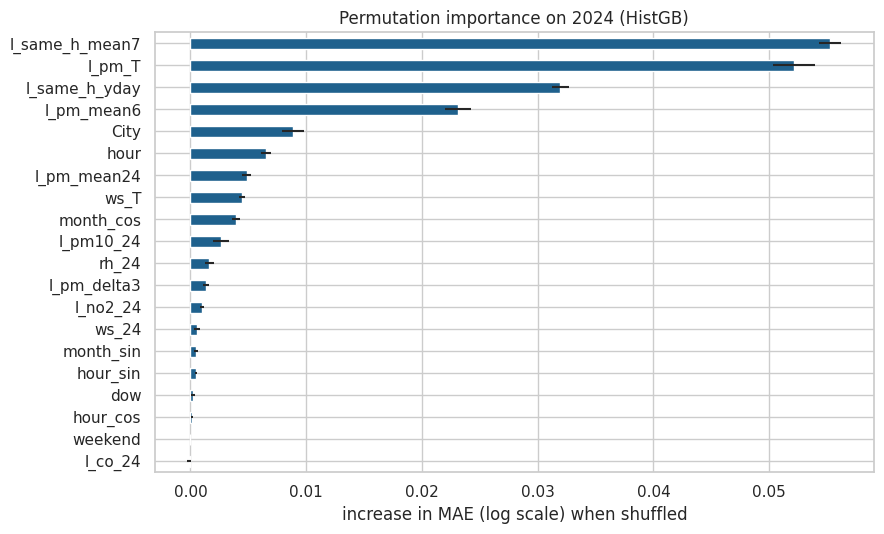

In [16]:
imp_sample = test.sample(n=min(6000, len(test)), random_state=SEED)
pi_ = permutation_importance(models[SEL], imp_sample[FEATS + ["City"]], imp_sample["y_log"], scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED)
imp = pd.DataFrame({"increase_in_MAE_log": pi_.importances_mean, "sd": pi_.importances_std}, index=FEATS + ["City"]).sort_values("increase_in_MAE_log", ascending=False)
display(savetab(imp.round(4), "18_permutation_importance"))
fig, ax = plt.subplots(figsize=(9, 5.5))
imp["increase_in_MAE_log"][::-1].plot.barh(xerr=imp["sd"][::-1], ax=ax, color="#1F618D")
ax.set_title(f"Permutation importance on 2024 ({SEL})"); ax.set_xlabel("increase in MAE (log scale) when shuffled")
savefig("11_permutation_importance")

**Interpretation.** The model mainly uses the same-hour average over the past week, the current level, the same hour yesterday and the last 6 hours: recent level plus daily rhythm. Wind speed at 21:00 is the most useful measured-weather feature (eighth overall); humidity, co-pollutants and calendar features add little once the recent PM2.5 history is known.

## Phase 6. Dose model and plan optimizer

$\text{Dose} = \sum_h C_h \times BR_{j(h)} \times 1\,\text{h}$ [µg], with $C_h$ the PM2.5 concentration and $BR$ the breathing rate of the task done in hour $h$. By the **rearrangement inequality**, $\sum a_i b_{\sigma(i)}$ is smallest when the largest $a$ is paired with the smallest $b$, so the heaviest task should go to the cleanest hours. AirShift enumerates every feasible plan (start hour × task order) and picks the exact minimum with one matrix product.

In [17]:
br = pd.DataFrame(ac.BREATHING_RATE_M3_PER_H).T.round(3); br.index = ["Adult (21 to <31 years)", "Youth (16 to <21 years)"]
print("Breathing rates in m3/hour (U.S. EPA Exposure Factors Handbook 2011, Table 6-2, means x 60):")
display(savetab(br, "19_breathing_rates"))
display(savetab(pd.DataFrame([{"scenario": sc.label, "group": sc.group, "tasks": ", ".join(f"{t.name} {t.hours}h ({t.intensity})" for t in sc.tasks),
                               "allowed window": f"{sc.window[0]:02d}:00 to {sc.window[1]:02d}:00", "usual start": f"{sc.fixed_start:02d}:00",
                               "feasible plans": len(ac.enumerate_plans(sc)[0])} for sc in ac.SCENARIOS.values()]), "20_scenarios", index=False))
print(inspect.getsource(ac.enumerate_plans))

Breathing rates in m3/hour (U.S. EPA Exposure Factors Handbook 2011, Table 6-2, means x 60):


,sedentary,light,moderate,high
Adult (21 to <31 years),0.252,0.72,1.56,3.00
Youth (16 to <21 years),0.318,0.72,1.56,2.94


,scenario,group,tasks,allowed window,usual start,feasible plans
0,Construction worker,adult,"Heavy lifting 2h (high), Site work 4h (moderate)",06:00 to 20:00,09:00,18
1,Delivery rider,adult,Delivery riding 8h (moderate),06:00 to 22:00,10:00,9
2,Street vendor,adult,Vending 6h (light),06:00 to 22:00,16:00,11
3,Student: sports practice,youth,"Sports 1h (high), Warm-up and drills 1h (moder...",06:00 to 19:00,17:00,24


def enumerate_plans(scenario):
    """All feasible plans: a start hour plus an order of the tasks, done back to back.

    Returns (plans, W) where W[p, h] is the breathing rate (m3/h) in clock hour h under plan p.
    """
    br = BREATHING_RATE_M3_PER_H[scenario.group]
    first, end = scenario.window
    orders = sorted(set(permutations(range(len(scenario.tasks)))))
    plans, rows = [], []
    for start in range(first, end - scenario.total_hours + 1):
        for order in orders:
            w = np.zeros(24)
            h = start
            for i in order:
                t = scenario.tasks[i]
                w[h:h + t.hours] = br[t.intensity]
                h += t.hours
            plans.append({"start": start, "order": order})
            rows.append(w)
    return plans, np.array(rows)



## Phase 7. Backtest on 2024: how much exposure would AirShift have avoided?

All plans are scored with the **true** 2024 concentrations.

| Plan | How it is chosen |
|---|---|
| Usual schedule | the scenario's fixed start time |
| Random (average) | average over all feasible plans |
| Climatology plan | best plan for the city's typical profile in that month (2020 to 2022) |
| Yesterday plan | best plan if tomorrow equals yesterday |
| AirShift (forecast only) | best plan for the point forecast |
| AirShift (robust) | best plan for the conformal upper bound |
| **AirShift (final)** | forecast plan with an optional uncertainty-aware fallback to the climatology plan, chosen on 2023 (never on the test year) |
| Oracle | best plan with perfect knowledge |

**Captured savings** $= (D_{random}-D_{plan})/(D_{random}-D_{oracle})$; **regret** $= D_{plan}/D_{oracle}-1$.

In [18]:
def backtest(split_name, cities):
    out = []
    part = frame[frame["split"] == split_name].copy(); part["yday"] = np.expm1(part["base_yday"])
    for c in cities:
        pc = part[part["City"] == c]; dates = pd.DatetimeIndex(sorted(pc["date"].unique()))
        arr = {k: day_arrays(pc, k, dates) for k in ["y", "pred", "lo", "hi", "clim", "yday"]}
        for sc in ac.SCENARIOS.values():
            plans, W = ac.enumerate_plans(sc); fi = ac.fixed_plan_index(sc, plans); hrs = np.where(W.sum(axis=0) > 0)[0]
            valid = ~np.isnan(arr["y"][:, hrs]).any(axis=1) & ~np.isnan(arr["pred"][:, hrs]).any(axis=1) & ~np.isnan(arr["clim"][:, hrs]).any(axis=1)
            if valid.sum() == 0:
                continue
            Dt = ac.plan_doses(arr["y"][valid], W); ix = np.arange(Dt.shape[0])
            choose = lambda a: np.argmin(ac.plan_doses(np.where(np.isnan(a[valid]), arr["clim"][valid], a[valid]), W), axis=1)
            pk = {"AirShift": choose(arr["pred"]), "AirShift (robust)": choose(arr["hi"]), "Climatology plan": choose(arr["clim"]),
                  "Yesterday plan": choose(arr["yday"]), "_lo": choose(arr["lo"])}
            res = pd.DataFrame({"City": c, "scenario": sc.label, "period": split_name, "date": dates[valid], "Usual schedule": Dt[:, fi],
                                "Random (average)": Dt.mean(axis=1), "Oracle": Dt.min(axis=1),
                                **{m: Dt[ix, pk[m]] for m in ["AirShift", "AirShift (robust)", "Climatology plan", "Yesterday plan"]}})
            stt = {m: np.array([plans[i]["start"] for i in pk[m]]) for m in ["AirShift", "AirShift (robust)", "_lo"]}
            res["confidence"] = [ac.confidence_label(a, b, c_) for a, b, c_ in zip(stt["_lo"], stt["AirShift"], stt["AirShift (robust)"])]
            out.append(res)
    return pd.concat(out, ignore_index=True)

bt = pd.concat([backtest("cal", CORE), backtest("test", CORE), backtest("newcity", NEW)], ignore_index=True)
bt["Region"] = bt["City"].map(meta["Region"])
bt["Hybrid: fall back when low"] = np.where(bt["confidence"] == "low", bt["Climatology plan"], bt["AirShift"])
bt["Hybrid: fall back unless high"] = np.where(bt["confidence"] == "high", bt["AirShift"], bt["Climatology plan"])
def captured(d, k):
    m = d[["Random (average)", "Oracle", k]].mean(); return (m["Random (average)"] - m[k]) / (m["Random (average)"] - m["Oracle"]) * 100
POLICIES = ["AirShift", "Hybrid: fall back when low", "Hybrid: fall back unless high"]
pol = pd.DataFrame({p_: {s_: captured(g, p_) for s_, g in bt[bt["period"] == "cal"].groupby("scenario")} for p_ in POLICIES + ["Climatology plan"]})
pol.loc["mean"] = pol.mean()
display(savetab(pol.round(2), "21_policy_selection_2023"))
FINAL_POLICY = pol.loc["mean", POLICIES].idxmax(); bt["AirShift (final)"] = bt[FINAL_POLICY]
print("Policy chosen on 2023 for 'AirShift (final)':", FINAL_POLICY)
bt.to_csv(TAB / "22_backtest_daily.csv.gz", index=False, compression="gzip")

METHODS = ["Usual schedule", "Random (average)", "Climatology plan", "Yesterday plan", "AirShift", "AirShift (robust)", "AirShift (final)", "Oracle"]
PLANNERS = ["Climatology plan", "Yesterday plan", "AirShift", "AirShift (robust)", "AirShift (final)"]
def summarise(d):
    m = d[METHODS].mean(); out = {"days": len(d)}
    for k in METHODS:
        out[f"saving_vs_usual_% | {k}"] = (1 - m[k] / m["Usual schedule"]) * 100
    for k in PLANNERS:
        out[f"captured_% | {k}"] = (m["Random (average)"] - m[k]) / (m["Random (average)"] - m["Oracle"]) * 100
        out[f"regret_% | {k}"] = (d[k] / d["Oracle"] - 1).mean() * 100
    return pd.Series(out)
b24 = bt[bt["period"] == "test"]
overall = b24.groupby("scenario").apply(summarise)
display(savetab(overall[["days"] + [f"saving_vs_usual_% | {k}" for k in ["Climatology plan", "AirShift", "AirShift (final)", "AirShift (robust)", "Oracle"]]].round(1), "23_backtest_saving_vs_usual"))
display(savetab(overall[[f"captured_% | {k}" for k in PLANNERS] + [f"regret_% | {k}" for k in PLANNERS]].round(1), "24_backtest_captured_and_regret"))

,AirShift,Hybrid: fall back when low,Hybrid: fall back unless high,Climatology plan
Construction worker,59.62,58.56,58.34,54.92
Delivery rider,57.04,55.56,55.59,51.89
Street vendor,61.28,59.85,59.42,56.87
Student: sports practice,56.00,54.82,55.11,52.48
mean,58.49,57.20,57.12,54.04


Policy chosen on 2023 for 'AirShift (final)': AirShift


,days,saving_vs_usual_% | Climatology plan,saving_vs_usual_% | AirShift,saving_vs_usual_% | AirShift (final),saving_vs_usual_% | AirShift (robust),saving_vs_usual_% | Oracle
scenario,,,,,,
Construction worker,9094.0,13.9,15.8,15.8,15.6,24.4
Delivery rider,9035.0,2.6,4.3,4.3,4.2,11.3
Street vendor,9035.0,16.5,18.3,18.3,18.2,26.2
Student: sports practice,9136.0,9.0,11.5,11.5,11.4,27.4


,captured_% | Climatology plan,captured_% | Yesterday plan,captured_% | AirShift,captured_% | AirShift (robust),captured_% | AirShift (final),regret_% | Climatology plan,regret_% | Yesterday plan,regret_% | AirShift,regret_% | AirShift (robust),regret_% | AirShift (final)
scenario,,,,,,,,,,
Construction worker,47.5,48.2,57.3,56.3,57.3,16.8,17.9,14.2,14.7,14.2
Delivery rider,44.3,44.2,55.3,54.4,55.3,10.9,12.2,9.2,9.6,9.2
Street vendor,50.0,48.6,58.9,58.6,58.9,15.6,17.5,13.3,13.7,13.3
Student: sports practice,45.8,44.0,53.3,52.9,53.3,34.6,38.1,31.0,31.9,31.0


**Interpretation.** On 2023 (not the test year) the plain forecast plan beat both fallback rules (58.5% captured against 57.2% and 57.1%), so 'AirShift (final)' is the forecast plan. On 2024 it captures 53% to 59% of the achievable improvement in every scenario, against 44% to 50% for the climatology plan and 44% to 48% for yesterday's pattern: about 9 to 11 percentage points better than the best simple planner, a clearly larger gap than in the five-city version. In absolute terms it means 15.8% less PM2.5 inhaled than a 09:00 start for the construction worker (oracle 24.4%), 18.3% for the street vendor (26.2%), 11.5% for student sports (27.4%) and 4.3% for the delivery rider (11.3%), whose 8-hour shift leaves little room to move.

Region,North,East,Northeast,Central,West,South
scenario,,,,,,
Construction worker,60.9,56.1,67.4,68.2,47.5,50.3
Delivery rider,57.4,53.3,71.4,67.7,47.0,49.3
Street vendor,62.0,56.7,76.5,71.2,53.7,50.5
Student: sports practice,55.1,53.4,63.2,64.0,42.9,48.8


Cities where AirShift (final) captures more than the climatology plan: 25 of 29


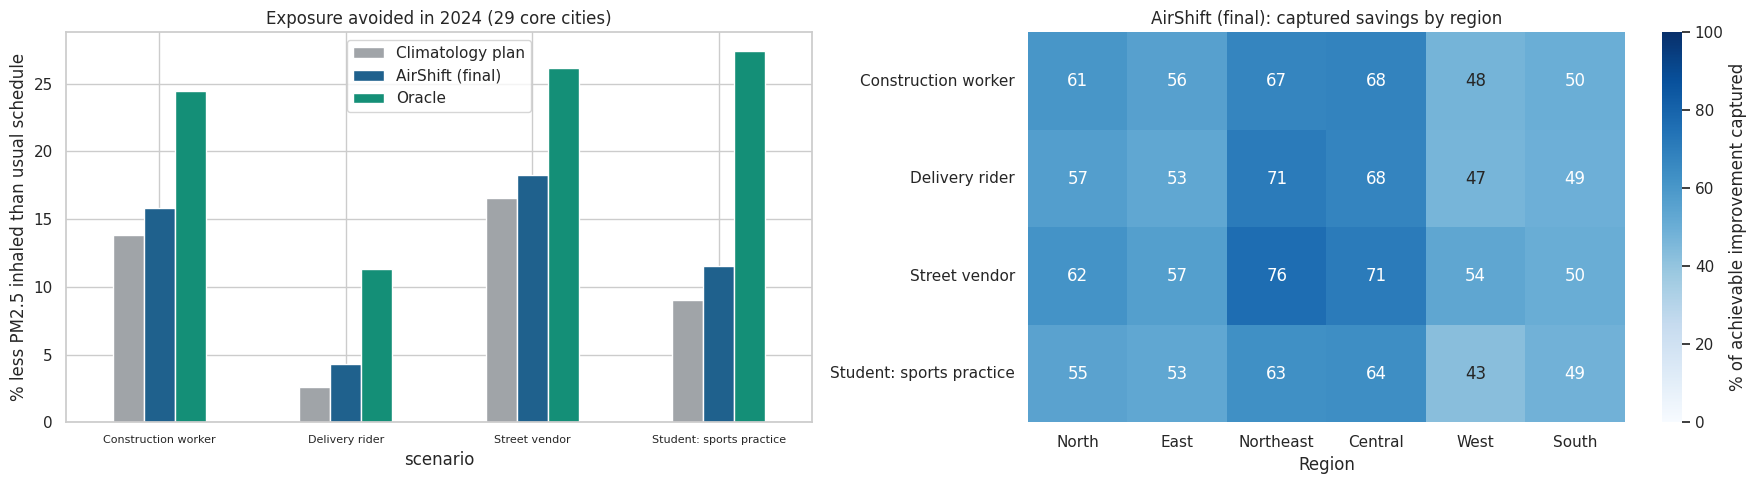

,days,median_diff_vs_usual_ug,p_vs_usual,p_vs_climatology,beats_climatology,same_as_climatology,worse_than_climatology
scenario,,,,,,,
Construction worker,9094,-54.99588,0.000000e+00,5.266775e-17,0.329888,0.376622,0.293490
Delivery rider,9035,-9.75000,6.358651e-280,1.166313e-31,0.308688,0.451134,0.240177
Street vendor,9035,-23.72904,0.000000e+00,2.389945e-20,0.312562,0.424903,0.262535
Student: sports practice,9136,-12.21507,0.000000e+00,1.473953e-11,0.405429,0.232815,0.361756


In [19]:
by_reg = b24.groupby(["scenario", "Region"]).apply(summarise)
capr = by_reg["captured_% | AirShift (final)"].unstack()[[r for r in REGIONS if r in b24["Region"].unique()]]
display(savetab(capr.round(1), "25_captured_by_region"))
by_city = b24.groupby(["City"]).apply(summarise)[["days", "captured_% | AirShift (final)", "captured_% | Climatology plan"]]
by_city = by_city.join(meta[["Region"]]).sort_values(["Region", "captured_% | AirShift (final)"])
savetab(by_city.round(1), "26_captured_by_city")
print("Cities where AirShift (final) captures more than the climatology plan:",
      int((by_city["captured_% | AirShift (final)"] > by_city["captured_% | Climatology plan"]).sum()), "of", len(by_city))

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
cols = {"saving_vs_usual_% | Climatology plan": "Climatology plan", "saving_vs_usual_% | AirShift (final)": "AirShift (final)", "saving_vs_usual_% | Oracle": "Oracle"}
overall[list(cols)].rename(columns=cols).plot.bar(ax=axes[0], color=["#A0A4A8", "#1F618D", "#148F77"], rot=0)
axes[0].set_ylabel("% less PM2.5 inhaled than usual schedule"); axes[0].set_title(f"Exposure avoided in 2024 ({len(CORE)} core cities)"); axes[0].tick_params(axis="x", labelsize=8)
sns.heatmap(capr, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=axes[1], cbar_kws={"label": "% of achievable improvement captured"})
axes[1].set_title("AirShift (final): captured savings by region"); axes[1].set_ylabel("")
savefig("12_backtest_results")

rows = []
for sname, g in b24.groupby("scenario"):
    a, u, cl = g["AirShift (final)"], g["Usual schedule"], g["Climatology plan"]
    rows.append({"scenario": sname, "days": len(g), "median_diff_vs_usual_ug": float(np.median(a - u)), "p_vs_usual": stats.wilcoxon(a, u).pvalue,
                 "p_vs_climatology": stats.wilcoxon(a, cl).pvalue, "beats_climatology": float((a < cl - 1e-9).mean()),
                 "same_as_climatology": float(np.isclose(a, cl).mean()), "worse_than_climatology": float((a > cl + 1e-9).mean())})
display(savetab(pd.DataFrame(rows).set_index("scenario"), "27_wilcoxon_tests"))

**Interpretation.** AirShift beats the climatology plan in 25 of 29 cities. Captured savings are highest in Central India (64% to 71%), the Northeast (63% to 77%, Guwahati only) and the North (55% to 62%), and lowest in the South (49% to 51%) and West (43% to 54%), where daily cycles are flatter or sea breezes make them less regular. Chennai is one of the four cities where the climatology plan does slightly better (45.8% against 42.1%). Wilcoxon tests are highly significant against both the usual schedule and the climatology plan (p < 10^-10). AirShift chooses a better plan than climatology on 31% to 41% of days, the same value on 23% to 45%, and a worse one on 24% to 36%.

### 7.1 Is the confidence label meaningful?
High: plans from the lower bound, point forecast and upper bound start within 1 hour of each other; medium: within 3 hours; low: otherwise.

In [20]:
conf = b24.assign(regret=(b24["AirShift"] / b24["Oracle"] - 1) * 100, regret_clim=(b24["Climatology plan"] / b24["Oracle"] - 1) * 100).groupby("confidence").agg(
    days=("regret", "size"), mean_regret_forecast_plan=("regret", "mean"), median_regret_forecast_plan=("regret", "median"),
    mean_regret_climatology_plan=("regret_clim", "mean")).reindex(["high", "medium", "low"])
conf["share_of_days"] = conf["days"] / conf["days"].sum()
display(savetab(conf.round(3), "28_confidence_vs_regret"))

,days,mean_regret_forecast_plan,median_regret_forecast_plan,mean_regret_climatology_plan,share_of_days
confidence,,,,,
high,27710,14.212,3.869,16.869,0.763
medium,3510,21.249,8.512,22.618,0.097
low,5080,29.077,10.229,31.776,0.140


**Interpretation.** On high-confidence days (76% of days) mean regret is 14.2% (median 3.9%); on low-confidence days (14%) it is 29.1% (median 10.2%), so the label separates good and risky days well. Unlike in the earlier five-city version, the climatology plan is worse than the forecast plan for every confidence level (16.9%, 22.6% and 31.8% regret), which is why no fallback rule was adopted.

### 7.2 Markov's and Chebyshev's inequalities for daily dose
For the construction worker on the usual schedule, $P(D\ge a)\le \mu/a$ (Markov) and $P(|D-\mu|\ge k\sigma)\le 1/k^2$ (Chebyshev), checked in every core city.

In [21]:
rows = []
g = b24[b24["scenario"] == "Construction worker"]
for c, d in g.groupby("City"):
    d = d["Usual schedule"]; mu, sd = d.mean(), d.std()
    for a_m in (1.5, 2.0):
        rows.append({"City": c, "bound": f"Markov a = {a_m} x mean", "bound_value": 1 / a_m, "observed": (d >= a_m * mu).mean()})
    for k in (2, 3):
        rows.append({"City": c, "bound": f"Chebyshev k = {k}", "bound_value": 1 / k ** 2, "observed": ((d - mu).abs() >= k * sd).mean()})
ineq = pd.DataFrame(rows); ineq["holds"] = ineq["observed"] <= ineq["bound_value"]
display(savetab(ineq.groupby("bound").agg(bound_value=("bound_value", "first"), min_observed=("observed", "min"), max_observed=("observed", "max"), all_hold=("holds", "all")), "29_dose_inequalities"))

,bound_value,min_observed,max_observed,all_hold
bound,,,,
Chebyshev k = 2,0.250000,0.024793,0.058011,True
Chebyshev k = 3,0.111111,0.000000,0.032258,True
Markov a = 1.5 x mean,0.666667,0.096234,0.246575,True
Markov a = 2.0 x mean,0.500000,0.003311,0.150235,True


**Interpretation.** All Markov and Chebyshev bounds hold in all 29 cities, and they are loose: at twice the mean, Markov allows up to 50% of days while 0.3% to 15% occur; at k = 2, Chebyshev allows 25% while 2.5% to 5.8% occur.

### 7.3 One day, step by step

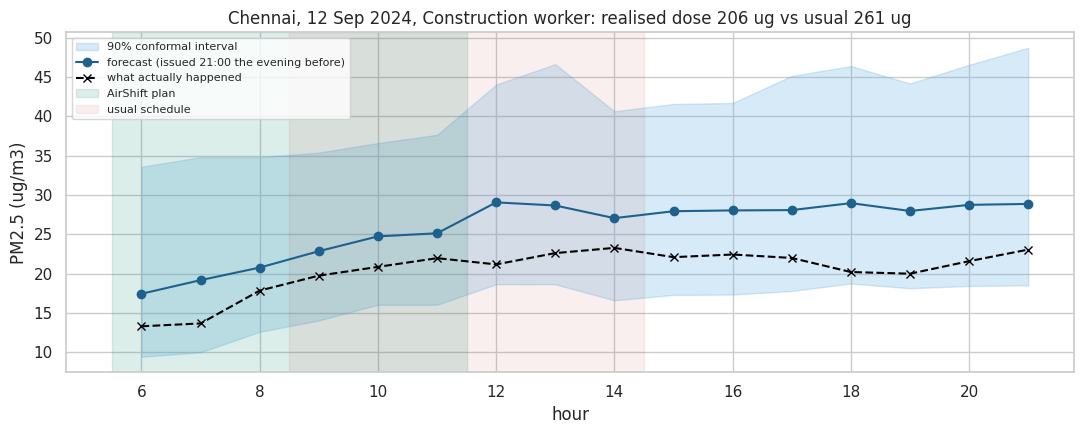

AirShift plan: start 06:00, task order ['Heavy lifting', 'Site work']


In [22]:
ex_city, ex_sc = "Chennai", ac.SCENARIOS["construction"]
cand = b24[(b24["City"] == ex_city) & (b24["scenario"] == ex_sc.label) & (b24["confidence"] == "high")].copy()
if cand.empty:
    cand = b24[(b24["City"] == ex_city) & (b24["scenario"] == ex_sc.label)].copy()
cand["gain"] = 1 - cand["AirShift"] / cand["Usual schedule"]
ex = cand.iloc[(cand["gain"] - cand["gain"].quantile(0.75)).abs().argsort().iloc[0]]
EX_DATE = ex["date"]
d = frame[(frame["City"] == ex_city) & (frame["date"] == EX_DATE)].set_index("hour")
conc = lambda col: d[col].reindex(range(24)).to_numpy()
plan, dose, plans, W, _ = ac.best_plan(conc("pred"), ex_sc)
hh = list(range(6, 22))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(hh, d.loc[hh, "lo"], d.loc[hh, "hi"], color="#5DADE2", alpha=0.25, label="90% conformal interval")
ax.plot(hh, d.loc[hh, "pred"], color="#1F618D", marker="o", label="forecast (issued 21:00 the evening before)")
ax.plot(hh, d.loc[hh, "y"], color="black", ls="--", marker="x", label="what actually happened")
ax.axvspan(plan["start"] - 0.5, plan["start"] + ex_sc.total_hours - 0.5, color="#148F77", alpha=0.15, label="AirShift plan")
ax.axvspan(ex_sc.fixed_start - 0.5, ex_sc.fixed_start + ex_sc.total_hours - 0.5, color="#B03A2E", alpha=0.08, label="usual schedule")
ax.set_xlabel("hour"); ax.set_ylabel("PM2.5 (ug/m3)"); ax.legend(fontsize=8, loc="upper left")
ax.set_title(f"{ex_city}, {EX_DATE:%d %b %Y}, {ex_sc.label}: realised dose {ex['AirShift']:.0f} ug vs usual {ex['Usual schedule']:.0f} ug")
savefig("13_example_day")
print(f"AirShift plan: start {plan['start']:02d}:00, task order {[ex_sc.tasks[i].name for i in plan['order']]}")

## Phase 8. New-city test: does AirShift work in a city it has never seen?
Fourteen cities started reporting too late to train on, including Vellore, Coimbatore and five north-eastern capitals. The model trained on the core cities is applied to them in 2024 without any change. Their "climatology plan" uses the typical day of core cities in the same region, and their intervals use the pooled conformal quantile.

In [23]:
nc = frame[(frame["split"] == "newcity") & frame["y"].notna()]
rows = []
for name, col in [("Same hour yesterday", "base_yday"), ("Regional climatology", "base_clim"), (SEL, f"pred_{SEL}")]:
    rows.append({"method": name, **scores(nc, nc[col])})
nc_tab = pd.DataFrame(rows).set_index("method")
display(savetab(nc_tab.round(3), "30_newcity_forecast"))
bn = bt[bt["period"] == "newcity"]
nsum = bn.groupby("scenario").apply(summarise)[["days", "saving_vs_usual_% | AirShift (final)", "captured_% | AirShift (final)", "captured_% | Climatology plan", "captured_% | Yesterday plan"]]
display(savetab(nsum.round(1), "31_newcity_backtest"))
ncity = bn.groupby("City").apply(summarise)[["days", "captured_% | AirShift (final)", "captured_% | Climatology plan"]].join(meta[["Region", "State"]])
display(savetab(ncity.round(1).sort_values("Region"), "32_newcity_by_city"))

,MAE,RMSE,MAE_log
method,,,
Same hour yesterday,12.547,23.169,0.409
Regional climatology,24.504,38.100,0.672
HistGB,10.205,18.452,0.343


,days,saving_vs_usual_% | AirShift (final),captured_% | AirShift (final),captured_% | Climatology plan,captured_% | Yesterday plan
scenario,,,,,
Construction worker,3148.0,17.0,55.6,42.1,46.3
Delivery rider,3113.0,3.8,54.3,40.0,43.4
Street vendor,3113.0,20.6,58.2,45.6,49.8
Student: sports practice,3171.0,16.3,52.0,40.5,41.6


,days,captured_% | AirShift (final),captured_% | Climatology plan,Region,State
City,,,,,
Bhopal,1241.0,77.5,67.7,Central,Madhya Pradesh
Bhubaneswar,1368.0,49.6,29.0,East,Odisha
Raipur,1432.0,51.2,45.3,East,Chhattisgarh
Agra,1222.0,70.6,63.8,North,Uttar Pradesh
Dehradun,877.0,61.8,34.0,North,Uttarakhand
Agartala,1014.0,50.1,45.4,Northeast,Tripura
Aizawl,672.0,29.3,2.3,Northeast,Mizoram
Gangtok,628.0,39.3,14.6,Northeast,Sikkim
Imphal,722.0,62.2,68.3,Northeast,Manipur


**Interpretation.** This is the strongest all-India result. In 14 cities the model never saw, it still forecasts better (MAE 10.2 against 12.5 for same hour yesterday and 24.5 for the regional typical day) and keeps coverage close to target (88.6%). Its plans capture 52% to 58% of the achievable improvement, against only 40% to 46% for borrowing the region's typical day. It works well in Bhopal (78%), Agra (71%), Imphal (62%), Dehradun (62%) and Shillong (61%), and poorly in Aizawl (29%) and Gangtok (39%). For Tamil Nadu the honest result is weaker: in Coimbatore (40% against 45%) and Vellore (29% against 36%) the regional typical day did better. Vellore has only about 73 complete days in 2024, so its estimate is uncertain; more months of local data would be needed to judge it fairly.

## Phase 9. Advisory cards in English, Marathi and Hindi

In [24]:
pred24 = conc("pred"); worst = ac.worst_block(pred24, ex_sc)
plans_, W_ = ac.enumerate_plans(ex_sc); fd = ac.plan_doses(pred24[None, :], W_)[0]
exp_saving = (1 - fd.min() / fd[ac.fixed_plan_index(ex_sc, plans_)]) * 100
for lang in ["en", "mr", "hi"]:
    print(ac.advisory_card(ex_city, f"{EX_DATE:%d %b %Y}", ex_sc, plan["start"], worst, exp_saving, ex["confidence"], lang)); print("-" * 60)

Chennai | Tomorrow, 12 Sep 2024
Best time for your work: 6 AM to 12 PM
Avoid if you can: 12 PM to 6 PM
Compared with your usual time (9 AM to 3 PM), this could cut the pollution you breathe in by about 19%.
Forecast confidence: high
------------------------------------------------------------
चेन्नई | उद्या, 12 Sep 2024
कामासाठी सर्वात चांगली वेळ: सकाळी 6 ते दुपारी 12
शक्य असल्यास टाळा: दुपारी 12 ते संध्याकाळी 6
नेहमीच्या वेळेपेक्षा (सकाळी 9 ते दुपारी 3) श्वासातून जाणारे प्रदूषण सुमारे 19% कमी होऊ शकते.
अंदाजाची खात्री: जास्त
------------------------------------------------------------
चेन्नई | कल, 12 Sep 2024
काम के लिए सबसे अच्छा समय: सुबह 6 से दोपहर 12 बजे तक
हो सके तो इस समय से बचें: दोपहर 12 से शाम 6 बजे तक
सामान्य समय (सुबह 9 से दोपहर 3 बजे तक) की तुलना में साँस से अंदर जाने वाला प्रदूषण लगभग 19% कम हो सकता है।
अनुमान पर भरोसा: ज़्यादा
------------------------------------------------------------


## Phase 10. Summary and exports for the dashboard

In [25]:
exp = frame[frame["split"].isin(["test", "newcity"])][["City", "date", "hour", "y", "pred", "lo", "hi", "clim"]].copy()
exp["date"] = exp["date"].dt.strftime("%Y-%m-%d")
exp.round(2).to_csv(APP / "forecasts.csv.gz", index=False, compression="gzip")
meta.reset_index().to_csv(APP / "city_meta.csv", index=False)
summary = {
    "core_cities": CORE, "new_cities": NEW, "regions": {r: sorted(meta.index[(meta["Region"] == r) & meta["group"].isin(["core", "new"])]) for r in REGIONS},
    "years": "2020 to 2024", "train": "2020 to 2022", "calibration": CAL_YEAR, "test": TEST_YEAR,
    "selected_model": SEL, "selected_params": SELECTED["params"], "final_policy": FINAL_POLICY,
    "median_within_day_ratio": {c: round(float(timing.loc[c, "median"]), 2) for c in CORE},
    "test_2024": {k: round(float(v_), 3) for k, v_ in test_tab.loc[SEL, ["MAE", "RMSE", "within_day_rank_corr", "skill_vs_best_baseline_%"]].items()},
    "best_baseline": best_base, "best_baseline_MAE": round(float(test_tab.loc[best_base, "MAE"]), 3),
    "conformal_coverage_2024": round(float(covr.loc["All core cities 2024", "conformal_coverage"]), 3),
    "conformal_coverage_newcities": round(float(covr.loc["New cities 2024 (pooled Q)", "conformal_coverage"]), 3),
    "backtest_2024": {s_: {"saving_vs_usual_pct": round(float(overall.loc[s_, "saving_vs_usual_% | AirShift (final)"]), 1),
                           "oracle_saving_vs_usual_pct": round(float(overall.loc[s_, "saving_vs_usual_% | Oracle"]), 1),
                           "captured_pct": round(float(overall.loc[s_, "captured_% | AirShift (final)"]), 1),
                           "captured_pct_climatology": round(float(overall.loc[s_, "captured_% | Climatology plan"]), 1)} for s_ in overall.index},
    "newcity_2024": {s_: {"captured_pct": round(float(nsum.loc[s_, "captured_% | AirShift (final)"]), 1),
                          "captured_pct_climatology": round(float(nsum.loc[s_, "captured_% | Climatology plan"]), 1)} for s_ in nsum.index},
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__}, "data_sha256": sha,
}
(APP / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps({k: summary[k] for k in ["selected_model", "final_policy", "test_2024", "conformal_coverage_2024", "conformal_coverage_newcities", "backtest_2024", "newcity_2024"]}, indent=2))

{
  "selected_model": "HistGB",
  "final_policy": "AirShift",
  "test_2024": {
    "MAE": 13.696,
    "RMSE": 25.191,
    "within_day_rank_corr": 0.458,
    "skill_vs_best_baseline_%": 18.108
  },
  "conformal_coverage_2024": 0.902,
  "conformal_coverage_newcities": 0.886,
  "backtest_2024": {
    "Construction worker": {
      "saving_vs_usual_pct": 15.8,
      "oracle_saving_vs_usual_pct": 24.4,
      "captured_pct": 57.3,
      "captured_pct_climatology": 47.5
    },
    "Delivery rider": {
      "saving_vs_usual_pct": 4.3,
      "oracle_saving_vs_usual_pct": 11.3,
      "captured_pct": 55.3,
      "captured_pct_climatology": 44.3
    },
    "Street vendor": {
      "saving_vs_usual_pct": 18.3,
      "oracle_saving_vs_usual_pct": 26.2,
      "captured_pct": 58.9,
      "captured_pct_climatology": 50.0
    },
    "Student: sports practice": {
      "saving_vs_usual_pct": 11.5,
      "oracle_saving_vs_usual_pct": 27.4,
      "captured_pct": 53.3,
      "captured_pct_climatology": 45.8

## Limitations
* **Historical evaluation only** (2024 test year); the dashboard's live mode uses a different forecast source.
* **City averages from up to three stations;** a worker's street-level exposure can differ, and a city's value can shift slightly when one of its stations is offline.
* **Outdoor PM2.5 only;** indoor exposure, masks, other pollutants and heat are not modelled.
* **Breathing rates are population means** from a U.S. reference.
* **Usual schedules are assumptions;** the captured-savings metric is reported because it does not depend on them.
* **Station metadata in the source dataset is imperfect** (for example some city labels are agency names), so stations were matched to cities by coordinates.
* **Not medical advice** and not a health-risk prediction.

**Future work:** live CPCB station data through an API key, station-level exposure, weather forecasts as inputs, combined heat and air-quality exposure for outdoor workers, and a field study with real workers.